# 配对状态 v2：粗化状态空间 + τ 扫描 + qc / att 检测评估

第一版（`20261107_KP_pair_state4d_infomap.ipynb`，输出 `20261107_pair_state4d/`）的问题：四维状态 12672 个，训练集只有约 260 万帧，Infomap 得到 1000–2000 个很小的簇（论文 56 个）。2026-11-07 讨论后的改动：

1. **粗化状态空间**：`D_xy` 不等宽 7 格（0–150 mm，近距离更细）+ 一个溢出格；`Δz` 4 格（关于 0 对称，内边界 = |Δz| 中位数）；`θ` 8 格（45°）。共 8 × 4 × 8 × 8 = 2048 个状态。训练集访问少于 `MIN_STATE_VISITS` 次的状态不进入转移图（避免只有几帧的状态各自成簇）。
2. **标注只分三类**：`qc`（quick circle、incomplete qc、Courtship）、`att`（attack、attempted att、Dash）、`wrap`。其余所有行为（approach、follow、chase、parallel circling、sneak、display、touch …）标为 `unknown`：不进评估，也**不算** `none`。注意按这个规则 K 组的 Chase 属于 unknown。
3. **τ 扫描（Step 3a）**：τ = 1–166 帧。两个指标：(a) 论文 Fig. S11a 的规则：最大簇大小突然跳变之前的 τ；(b) 只用训练集做留一实验交叉验证，看 qc / att / wrap 的可分性（AUC）。扫描选出的 τ 加到 `TAUS = [7, 17]` 里一起完整分析。行为时长（qc 0.75–4 s，att 5 帧–0.75 s）画在扫描图上，也作为平滑窗口（取下限）。
4. **成功标准**（Step 5）：qc 帧、att 帧能否和其他帧（none + 其他已知类别）分开。用训练集估计每个簇的 P(qc | 簇)、P(att | 簇)，在测试集（K_1_3、P_1_3）上评估：ROC/AUC、在训练集定的阈值下的精确率/召回率、按 bout 的检出率。

其余设定不变：状态变量 (D_xy, Δz, θ_a, θ_b)；`FM`（F 永远是 a，FM1+FM2 合并）和 `MM`（M1M2+M2M1 对称化）两个状态空间；训练 = K_1_1、K_1_2、P_1_1、P_1_2，测试 = K_1_3、P_1_3（同一批鱼的第 3 次录像）。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261107_pair_state4d_coarse/`。命名：`<步骤>_<名称>__<单元>__<参数>__<集合>.<扩展名>`。本 notebook 只给数值和图，不下结论。

## 参数

所有设置都在下面这个单元。`LABEL_CLASSES` 的顺序 = 同一配对的标注重叠时的优先级（排在前面的优先）。没列出的行为都记为 `unknown`。`DURATION_S` 是你估计的行为时长；平滑窗口 `SMOOTH_FRAMES` 取时长下限。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261107_pair_state4d_coarse_v2"
OUTPUT_ROOT = None    # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
# Two state spaces. FM: F is always fish a, FM1 and FM2 pooled. MM: both orders pooled (symmetrised).
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
FPS_NOMINAL = 166.0
DPI = 200
THUMB_WIDTH = 900        # also the width of the figures shown inside this notebook

# --- Step 0
MIN_XY_MM = 1.0          # horizontal pec-pec distance or horizontal head-pec length below this -> frame unusable
HEAD_PEC_MAX_MM = None   # optional: drop a fish-frame whose 3D head-pec distance exceeds this (mm); None = off

# --- Step 1
CLOSE_MM = 40.0          # "close" panels of P(theta_a, theta_b)
MAX_LAG_S = 5.0

# --- Step 2: bins (edges from the training set only)
D_EDGES_MM = [0, 10, 20, 30, 45, 65, 100, 150]   # non-uniform, finer at close range
D_OVERFLOW = True        # one more open bin [150 mm, inf)
N_BINS_DZ = 4            # even; symmetric about 0; inner edges at quantiles of |dz| (train, all copies)
N_BINS_THETA = 8
MIN_STATE_VISITS = 20    # states seen fewer times in a set are left out of that set's graph

# --- Step 2b / 5: BORIS. Order = priority where bouts of one pair overlap (first wins).
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "qc": ["quick circle", "incomplete qc", "courtship"],
    "att": ["attack", "attempted att", "dash"],
}
DETECT_CLASSES = ["qc", "att", "wrap"]
DURATION_S = {"qc": (0.75, 4.0), "att": (5 / FPS_NOMINAL, 0.75), "wrap": (0.75, None)}   # user estimate
SMOOTH_FRAMES = {c: max(1, int(round(lo * FPS_NOMINAL))) for c, (lo, _hi) in DURATION_S.items()}
PRIOR_FRAMES = 50.0      # shrinkage of P(class | cluster) towards the overall rate
MIN_POS = 100            # a class needs at least this many labelled frames (train and test) to be evaluated

# --- Step 3a: tau scan
TAU_SCAN = [1, 2, 3, 5, 7, 10, 14, 17, 20, 25, 30, 40, 50, 70, 100, 124, 166]
N_TRIALS_SCAN = 50
ADD_SCAN_TAUS = True     # also analyse in full: the paper-rule tau and the best LOEO-AUC tau per class

# --- Step 3: transitions and Infomap
TAUS = [7, 17]           # frames, always analysed in full
KEEP_SELF_LOOPS = True
N_TRIALS = 500
INFOMAP_SEED = 20261107
INFOMAP_WORKERS = 6
COVERAGE = 0.95          # "selected" clusters = largest clusters up to this share of frames
MAX_MATRIX = 40          # at most this many clusters drawn in the cluster x cluster matrix (rest pooled)
N_SHUFFLE = 100
TOP_SHOW = 12            # clusters drawn in cluster maps / usage figures

# --- Step 5 ethograms: (experiment, class, unit, window seconds); window placed where the class is densest
ETHOGRAM_SPECS = [("20251225_K_1_3_FCMC", "qc", "FM", 30.0), ("20260112_P_1_3_FCMC", "qc", "FM", 30.0),
                  ("20251225_K_1_3_FCMC", "att", "MM", 10.0), ("20260112_P_1_3_FCMC", "att", "MM", 10.0)]

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}; smoothing frames {SMOOTH_FRAMES}")

36 parameters; run 20261107_pair_state4d_coarse; smoothing frames {'qc': 124, 'att': 5, 'wrap': 124}


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录、定义保存图和读写中间结果的函数。`params.json` 在这里写入参数、日期、库版本。重跑任何一步之前先运行这个单元。新增的计算逻辑在 `scripts/analysis/pair_state4d.py`（有单元测试 `tests/test_pair_state4d.py`）。

In [2]:
import os
import sys
import json
import time
import platform
import importlib

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap, BoundaryNorm
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import Image as IPImage, display

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

importlib.reload(P4)

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
ALL_EXPERIMENTS = list(TRAIN_EXPERIMENTS) + list(TEST_EXPERIMENTS)
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}
if set(TRAIN_EXPERIMENTS) & set(TEST_EXPERIMENTS):
    raise ValueError("an experiment is in both TRAIN and TEST")


def _allow_listed(experiment, final):
    # split.csv is not used here; only the experiments named in the parameter cell may be read.
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed


def save_fig(fig, step, name, unit, params, set_name, show=False, dpi=None):
    # The only way figures are written: png + thumbnail + row in figures_index.csv.
    p = L.save_fig(fig, step, name, unit, params, set_name, dpi=dpi)
    if show:
        display(IPImage(filename=str(L.thumbs / p.name)))
    return p


def copy_name(a, b):
    return f"{a}{b}"   # FM1, FM2, M1M2, M2M1


COPIES = {u: [copy_name(a, b) for a, b in pairs] for u, pairs in UNITS.items()}
COPY_PAIR = {copy_name(a, b): (a, b) for pairs in UNITS.values() for a, b in pairs}
PAIR_COPIES = ["FM1", "FM2", "M1M2"]           # the three physical pairs, one order each
UNIT_OF = {cp: u for u, cps in COPIES.items() for cp in cps}
PAIR_COLOR = {"FM1": "#1f5fa8", "FM2": "#2e8b3e", "M1M2": "#8e44ad", "M2M1": "#c0392b"}
CLASS_COLOR = {"wrap": "#d62728", "qc": "#ff7f0e", "att": "#7f3c8d", "unknown": "#c7c7c7"}


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def exp_group(e):
    return M.parse_experiment(e)[0]


PRE = {"hpmax": HEAD_PEC_MAX_MM}
STATE_P = {"dmax": D_EDGES_MM[-1], "bd": len(D_EDGES_MM) - 1, "dnu": True, "of": bool(D_OVERFLOW),
           "bz": N_BINS_DZ, "bth": N_BINS_THETA, "minv": MIN_STATE_VISITS}


def tau_p(tau):
    return {"tau": int(tau), **STATE_P}


def lib_versions():
    import matplotlib as _mpl, scipy as _sp, PIL as _pil
    out = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scipy": _sp.__version__, "matplotlib": _mpl.__version__, "pillow": _pil.__version__}
    for mod in ("igraph", "sklearn"):
        try:
            out[mod] = getattr(importlib.import_module(mod), "__version__", "unknown")
        except ImportError:
            out[mod] = None
    return out


L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"),
                        "output_dir": str(L.root), "review_root": str(REVIEW_ROOT),
                        "paths_config": str(_CONFIG), "platform": platform.platform(),
                        "libraries": lib_versions()})


def load_exp(e):
    return L.load_npz("00", "pairvars", "all", PRE, exp_short(e))


def gather(set_name, copies):
    # All frames of the set, block by block (experiment x copy); segment ids made unique per block.
    vals, seg, exp, cop, frame = [], [], [], [], []
    off = 0
    for ei, e in enumerate(SETS[set_name]):
        z = load_exp(e)
        for ci, cp in enumerate(copies):
            v = z[f"vars_{cp}"].astype(np.float64)
            s = z[f"seg_{cp}"].astype(np.int64)
            s = np.where(s >= 0, s + off, -1)
            if (s >= 0).any():
                off = int(s.max()) + 1
            vals.append(v)
            seg.append(s)
            exp.append(np.full(len(v), ei, np.int16))
            cop.append(np.full(len(v), ci, np.int8))
            frame.append(z["frames"].astype(np.int64))
    return {"vals": np.concatenate(vals), "seg": np.concatenate(seg), "exp": np.concatenate(exp),
            "copy": np.concatenate(cop), "frame": np.concatenate(frame),
            "exp_names": list(SETS[set_name]), "copy_names": list(copies)}


INFOMAP = S.resolve_infomap_backend()
BACKEND_TAG = f"{INFOMAP['backend']} {INFOMAP['version']}"
L.update_params("infomap", {**INFOMAP, "N_TRIALS": N_TRIALS, "seed": INFOMAP_SEED,
                            "KEEP_SELF_LOOPS": KEEP_SELF_LOOPS, "workers": INFOMAP_WORKERS})
print("Infomap backend:", BACKEND_TAG)


def load_micro(unit, set_name):
    return L.load_npz("02", "microstates", unit, STATE_P, set_name)


def graph_input(counts, state_frames):
    # Occupied states with at least MIN_STATE_VISITS frames; optional self-loop removal; row-normalised.
    c = sparse.csr_matrix(counts, dtype=np.float64)
    occ = (np.asarray(c.sum(axis=1)).ravel() > 0) | (np.asarray(c.sum(axis=0)).ravel() > 0)
    keep = np.flatnonzero(occ & (np.asarray(state_frames) >= MIN_STATE_VISITS))
    sub = c[keep][:, keep].tolil()
    if not KEEP_SELF_LOOPS:
        sub.setdiag(0)
    sub = sub.tocsr()
    sub.eliminate_zeros()
    return keep, S.row_normalize(sub)


def run_jobs(jobs, trials):
    from concurrent.futures import ProcessPoolExecutor
    if INFOMAP_WORKERS <= 1:
        return {k: S.run_infomap(p, trials, INFOMAP_SEED, INFOMAP["backend"]) for k, p in jobs}
    with ProcessPoolExecutor(max_workers=INFOMAP_WORKERS) as ex:
        fut = {k: ex.submit(S.run_infomap, p, trials, INFOMAP_SEED, INFOMAP["backend"]) for k, p in jobs}
        return {k: f.result() for k, f in fut.items()}


def relabel(raw, keep, state_frames):
    # Renumber modules by covered frames (0 = most); states outside the graph get -1.
    lab = np.full(N_STATES, -1, dtype=np.int64)
    lab[keep] = raw
    k = int(raw.max()) + 1
    cover = np.bincount(lab[keep], weights=state_frames[keep], minlength=k)
    order = np.lexsort((np.arange(k), -cover))
    new = np.empty(k, dtype=np.int64)
    new[order] = np.arange(k)
    out = np.full(N_STATES, -1, dtype=np.int64)
    out[keep] = new[raw]
    return out, cover[order]




def labels_for(mic):
    # BORIS label of every row of a microstate table (filled in Step 2b).
    out = np.empty(len(mic["state"]), dtype=object)
    for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
        for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            out[m] = FRAME_LABELS[(e, cp)]
    return out


def blocks_of(mic):
    # One id per (experiment, copy) block: smoothing and bouts never cross blocks.
    return mic["exp"].astype(np.int64) * 10 + mic["copy"].astype(np.int64)


TAUS_FULL = {u: list(TAUS) for u in UNITS}   # extended by the tau scan (Step 3a)

print("output folder", L.root)
print("copies", COPIES)

Infomap backend: python-igraph 1.0.0
output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261107_pair_state4d_coarse
copies {'FM': ['FM1', 'FM2'], 'MM': ['M1M2', 'M2M1']}


## Step 0 — 读数据、算四个状态变量、连续片段、缺口统计

**做什么**：对 6 个实验读入审核后的 F/M1/M2 三节点 3D 坐标（mm）；对 4 个有序配对（FM1、FM2、M1M2、M2M1）算 `(D_xy, Δz, θ_a, θ_b)`；某帧任一变量无定义（坐标缺失、审核未接受、pec 水平距离或 head-pec 水平长度 < `MIN_XY_MM`）就记为不可用。连续可用帧构成片段，转移只在片段内部计数。

**输入**：review package（`review_data.npz` + 身份审核账本）。

**输出**：`data/00_pairvars__all__base__<实验>.npz`（每帧四个变量和片段号）、`data/00_gap_table__all__base__all.csv`（每个实验 × 三个配对：可用比例、手动删除 / 跟踪丢失 / 距离过近的比例、片段数、最长片段、缺口 p99）、图 `00_head_pec`（head-pec 3D 距离分布，用来决定要不要设 `HEAD_PEC_MAX_MM`）。

20251225_K_1_1_FCMC: 348600 frames @ 166.0 fps, review-blocked 3.41%, head-pec removed fish-frames 0  (2 s)


20251225_K_1_2_FCMC: 348600 frames @ 166.0 fps, review-blocked 5.97%, head-pec removed fish-frames 0  (2 s)


20260112_P_1_1_FCMC: 348600 frames @ 166.0 fps, review-blocked 5.27%, head-pec removed fish-frames 0  (2 s)


20260113_P_1_2_FCMC: 348600 frames @ 166.0 fps, review-blocked 3.86%, head-pec removed fish-frames 0  (2 s)


20251225_K_1_3_FCMC: 348600 frames @ 166.0 fps, review-blocked 6.98%, head-pec removed fish-frames 0  (2 s)


20260112_P_1_3_FCMC: 348600 frames @ 166.0 fps, review-blocked 6.16%, head-pec removed fish-frames 0  (2 s)
  csv data/00_gap_table__all__base__all.csv  rows 18
         experiment   set pair  frames  usable_percent  manually_removed_percent  tracking_lost_percent  too_close_or_vertical_percent  first_usable_s  n_segments  longest_segment_s  median_segment_s  gap_p99_frames
20251225_K_1_1_FCMC train  FM1  348600           95.62                      3.41                   0.36                           0.61           34.92         777             110.05              0.04          236.27
20251225_K_1_1_FCMC train  FM2  348600           95.80                      3.41                   0.19                           0.60           34.92         641              79.93              0.05          274.59
20251225_K_1_1_FCMC train M1M2  348600           95.99                      3.41                   0.42                           0.19           34.92         596             129.49          

  fig figures/00_head_pec__all__base__all.png


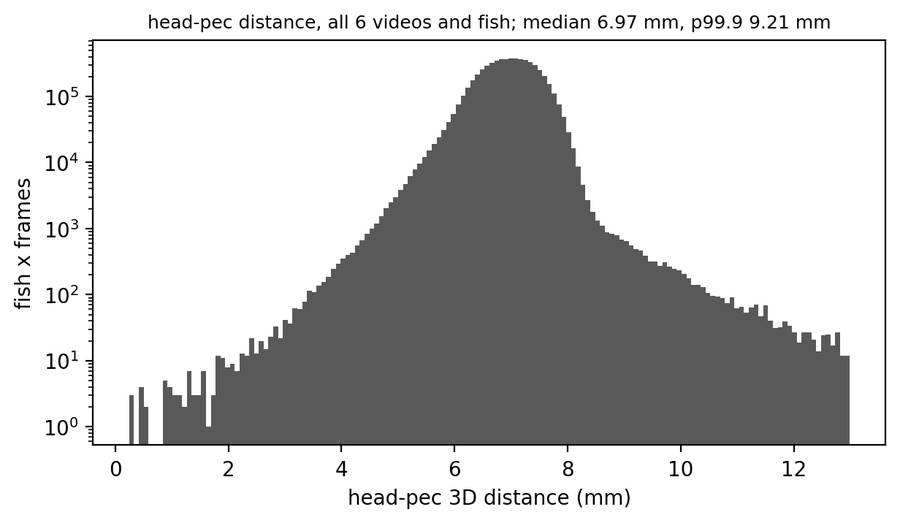

In [3]:
# Step 0: load, pair variables, segments, gap table.
L.clear_log("00")
gap_rows, hp_parts = [], []
for e in ALL_EXPERIMENTS:
    t0 = time.time()
    tr = M.load_trial(e, final=True)
    nodes = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    frames = np.asarray(tr["frames"], dtype=np.int64)
    fps = float(tr["fps"])
    hp = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)   # (T, 3 fish)
    hp_parts.append(hp[np.isfinite(hp)])
    n_hp = 0
    if HEAD_PEC_MAX_MM is not None:
        bad = np.isfinite(hp) & (hp > HEAD_PEC_MAX_MM)
        nodes[bad] = np.nan
        n_hp = int(bad.sum())
    arrays = {"frames": frames, "blocked": blocked, "fps": np.array(fps)}
    for cp, (a, b) in COPY_PAIR.items():
        v = P4.pair_variables(nodes, a, b, MIN_XY_MM)
        ok = np.isfinite(v).all(axis=1)
        arrays[f"vars_{cp}"] = v.astype(np.float32)
        arrays[f"seg_{cp}"] = S.segment_ids(ok).astype(np.int32)
        if cp in PAIR_COPIES:
            ia, ib = P4.FISH.index(a), P4.FISH.index(b)
            fin = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3))   # head and pec of both
            code = np.zeros(len(v), np.int8)
            code[blocked] = 1
            code[~blocked & ~fin] = 2
            code[~blocked & fin & ~ok] = 3
            g0, g1 = S.bool_runs(~ok)
            s0, s1 = S.bool_runs(ok)
            gaps = g1 - g0
            first = int(np.argmax(ok)) if ok.any() else -1
            gap_rows.append({
                "experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test", "pair": cp,
                "frames": len(v), "usable_percent": 100.0 * ok.mean(),
                "manually_removed_percent": 100.0 * (code == 1).mean(),
                "tracking_lost_percent": 100.0 * (code == 2).mean(),
                "too_close_or_vertical_percent": 100.0 * (code == 3).mean(),
                "first_usable_s": first / fps if first >= 0 else np.nan,
                "n_segments": len(s0), "longest_segment_s": float((s1 - s0).max() / fps) if len(s0) else 0.0,
                "median_segment_s": float(np.median(s1 - s0) / fps) if len(s0) else 0.0,
                "gap_p99_frames": float(np.percentile(gaps, 99)) if len(gaps) else 0.0,
            })
    L.save_npz(arrays, "00", "pairvars", "all", PRE, exp_short(e), verbose=False)
    print(f"{e}: {len(frames)} frames @ {fps:.1f} fps, review-blocked {100 * blocked.mean():.2f}%, "
          f"head-pec removed fish-frames {n_hp}  ({time.time() - t0:.0f} s)")

GAPS = pd.DataFrame(gap_rows)
L.save_csv(GAPS, "00", "gap_table", "all", PRE, "all")
print(GAPS.round(2).to_string(index=False))

hp_all = np.concatenate(hp_parts)
fig, ax = plt.subplots(figsize=(7, 3.6))
hi = float(np.percentile(hp_all, 99.95)) * 1.3
ax.hist(hp_all[hp_all <= hi], bins=150, color="0.35")
ax.set_yscale("log")
ax.set_xlabel("head-pec 3D distance (mm)")
ax.set_ylabel("fish x frames")
if HEAD_PEC_MAX_MM is not None:
    ax.axvline(HEAD_PEC_MAX_MM, color="k", ls="--")
ax.set_title(f"head-pec distance, all 6 videos and fish; median {np.median(hp_all):.2f} mm, "
             f"p99.9 {np.percentile(hp_all, 99.9):.2f} mm", fontsize=9)
save_fig(fig, "00", "head_pec", "all", PRE, "all", show=True)
L.log("00", "done")

## Step 1 — 状态变量的分布与时间尺度

**做什么**（训练集、测试集分别画）：
- `01_dist`：三个配对的 `D_xy`、`Δz` 分布。FM 的 Δz = z_F − z_M（正 = 雌鱼在上）；M1M2 的 Δz = z_M1 − z_M2。
- `01_theta_joint`：P(θ_a, θ_b)，仿论文 Fig. 4b。上排全部距离，下排只用 `D_xy < CLOSE_MM`。横轴 θ_a（FM 是 F；M1M2 是 M1），纵轴 θ_b。
- `01_dxy_dz`：P(D_xy, Δz)，看"上下错开"和"水平错开"怎么组合。
- `01_acf`（训练集）：六个量（D_xy、Δz、cos/sin θ_a、cos/sin θ_b）在片段内的自相关，仿 Fig. 2b；`data/01_acf_times` 是 1/e 时间。

这一步只是描述，不参与后面的选择。

  fig figures/01_dist__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


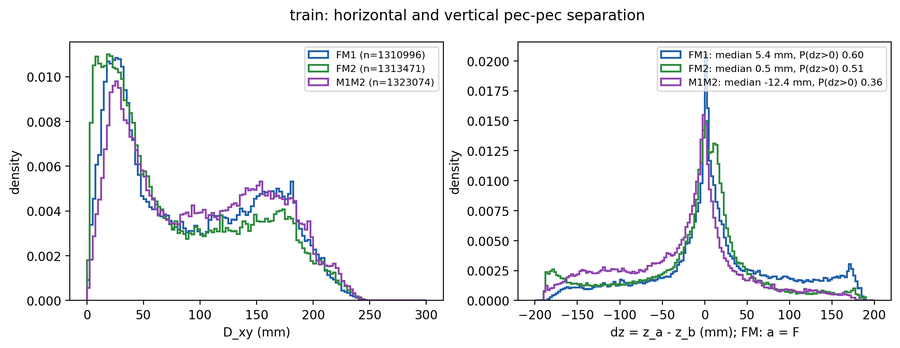

  fig figures/01_theta_joint__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


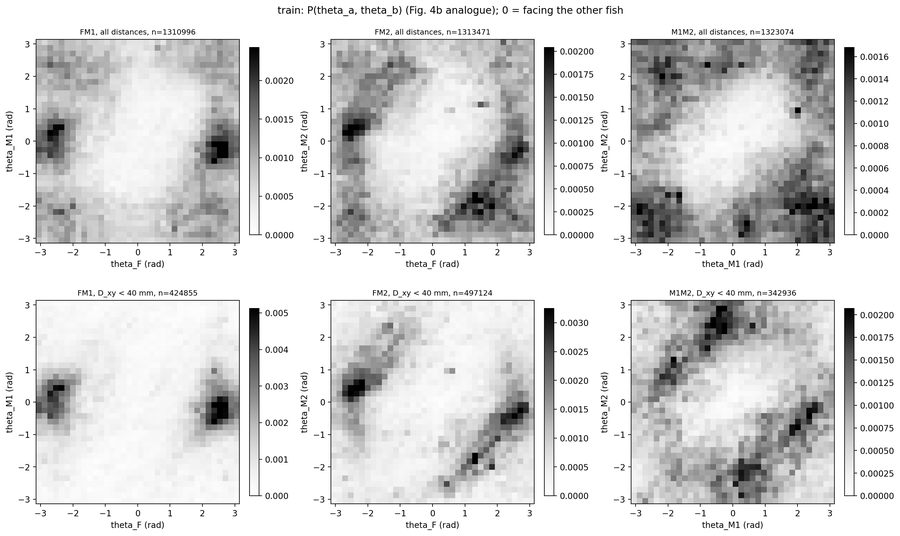

  fig figures/01_dxy_dz__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/01_dist__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


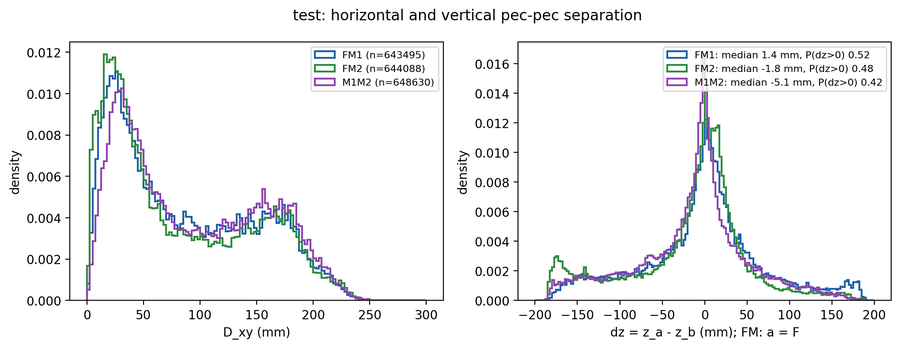

  fig figures/01_theta_joint__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


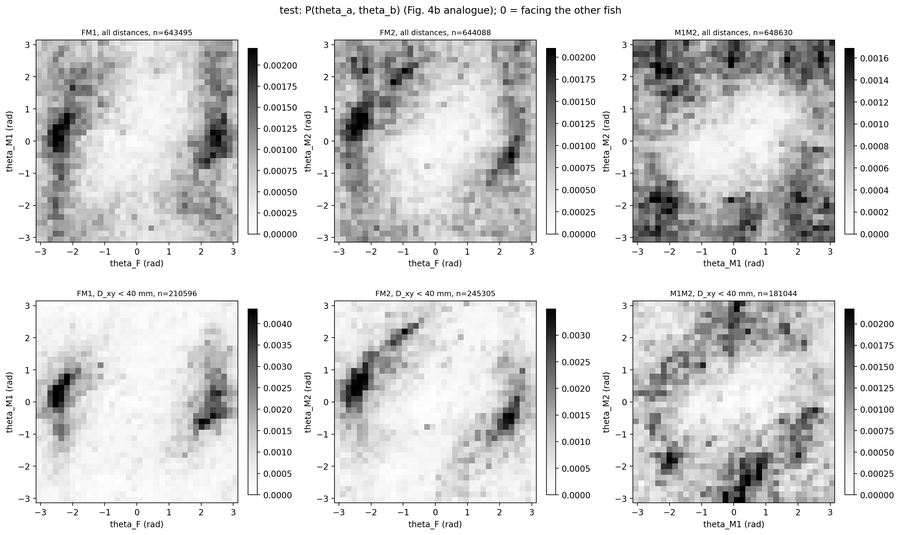

  fig figures/01_dxy_dz__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/01_acf__FM__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


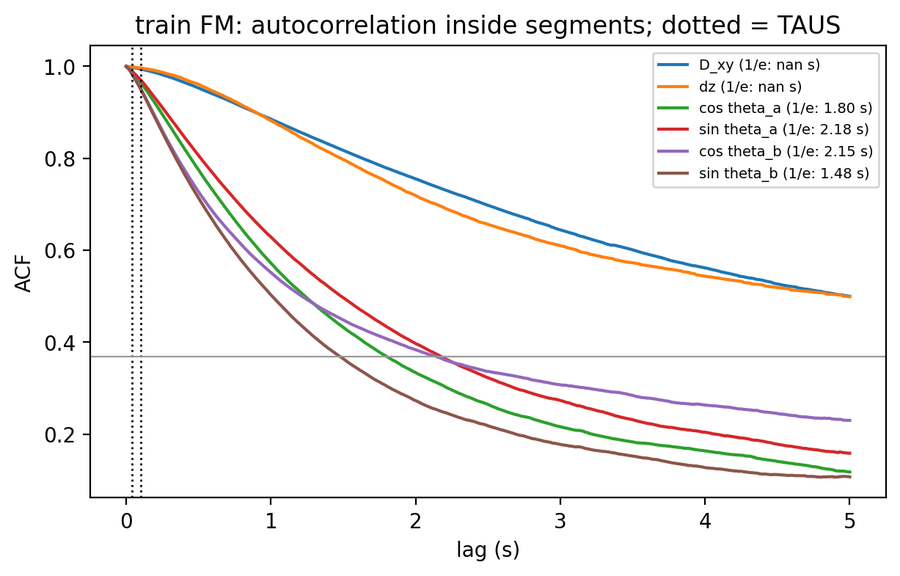

  fig figures/01_acf__MM__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


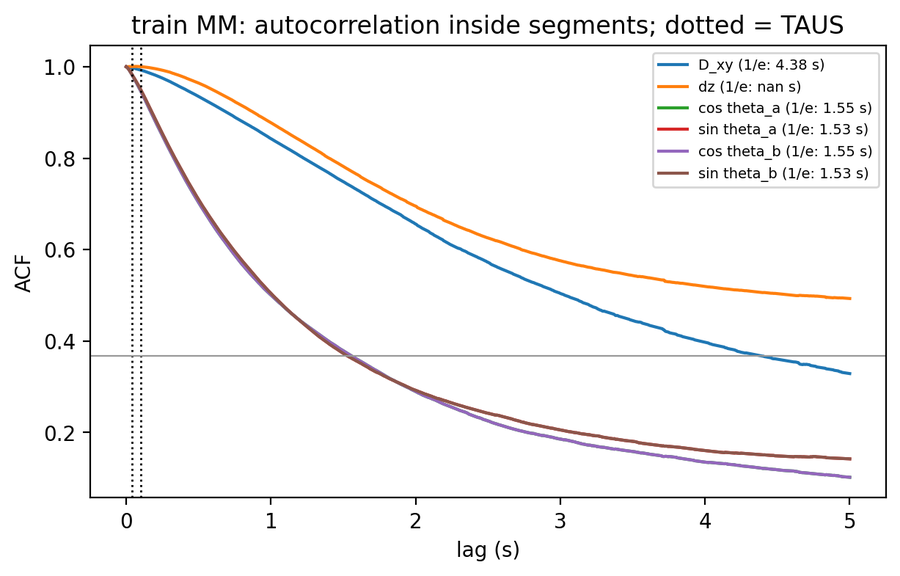

  csv data/01_acf_times__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.csv  rows 12
unit    variable  tau_1e_s
  FM        D_xy       NaN
  FM          dz       NaN
  FM cos theta_a     1.804
  FM sin theta_a     2.181
  FM cos theta_b     2.149
  FM sin theta_b     1.482
  MM        D_xy     4.384
  MM          dz       NaN
  MM cos theta_a     1.555
  MM sin theta_a     1.527
  MM cos theta_b     1.555
  MM sin theta_b     1.527


In [4]:
# Step 1: distributions (Fig. 4 analogue) and autocorrelation times.
L.clear_log("01")
TH_BINS = np.linspace(-np.pi, np.pi, 37)
for set_name in SETS:
    g = gather(set_name, PAIR_COPIES)
    v, cop = g["vals"], g["copy"]
    ok = np.isfinite(v).all(axis=1)
    # D_xy and dz
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ci, cp in enumerate(PAIR_COPIES):
        m = ok & (cop == ci)
        axes[0].hist(v[m, 0], bins=np.linspace(0, 300, 121), density=True, histtype="step", lw=1.5,
                     color=PAIR_COLOR[cp], label=f"{cp} (n={m.sum()})")
        axes[1].hist(v[m, 1], bins=np.linspace(-200, 200, 161), density=True, histtype="step", lw=1.5,
                     color=PAIR_COLOR[cp], label=f"{cp}: median {np.median(v[m, 1]):.1f} mm, "
                                                  f"P(dz>0) {np.mean(v[m, 1] > 0):.2f}")
    axes[0].set_xlabel("D_xy (mm)")
    axes[1].set_xlabel("dz = z_a - z_b (mm); FM: a = F")
    for ax in axes:
        ax.set_ylabel("density")
        ax.legend(fontsize=8)
    fig.suptitle(f"{set_name}: horizontal and vertical pec-pec separation")
    save_fig(fig, "01", "dist", "all", STATE_P, set_name, show=True)
    # P(theta_a, theta_b)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
    for row, close in enumerate((False, True)):
        for ci, cp in enumerate(PAIR_COPIES):
            m = ok & (cop == ci)
            if close:
                m &= v[:, 0] < CLOSE_MM
            H, _, _ = np.histogram2d(v[m, 2], v[m, 3], bins=[TH_BINS, TH_BINS])
            H = H / max(H.sum(), 1)
            ax = axes[row, ci]
            im = ax.imshow(H.T, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], cmap="Greys",
                           vmin=0, vmax=np.percentile(H[H > 0], 99.5) if (H > 0).any() else 1)
            a, b = COPY_PAIR[cp]
            ax.set_xlabel(f"theta_{a} (rad)")
            ax.set_ylabel(f"theta_{b} (rad)")
            ax.set_title(f"{cp}, {'D_xy < %g mm' % CLOSE_MM if close else 'all distances'}, n={m.sum()}", fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{set_name}: P(theta_a, theta_b) (Fig. 4b analogue); 0 = facing the other fish")
    save_fig(fig, "01", "theta_joint", "all", STATE_P, set_name, show=True)
    # P(D_xy, dz)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ci, cp in enumerate(PAIR_COPIES):
        m = ok & (cop == ci)
        H, xe, ye = np.histogram2d(v[m, 0], v[m, 1], bins=[np.linspace(0, 250, 51), np.linspace(-200, 200, 81)])
        im = axes[ci].imshow(H.T, origin="lower", extent=[xe[0], xe[-1], ye[0], ye[-1]], aspect="auto",
                             cmap="viridis", norm=LogNorm(vmin=1, vmax=max(H.max(), 2)))
        axes[ci].set_xlabel("D_xy (mm)")
        axes[ci].set_ylabel("dz (mm)")
        axes[ci].set_title(cp, fontsize=9)
        fig.colorbar(im, ax=axes[ci], fraction=0.046, label="frames")
    fig.suptitle(f"{set_name}: joint distribution of D_xy and dz (log colour)")
    save_fig(fig, "01", "dxy_dz", "all", STATE_P, set_name)

# autocorrelation (training set, per unit)
acf_rows = []
for unit in UNITS:
    g = gather("train", COPIES[unit])
    v, seg = g["vals"], g["seg"]
    use = seg >= 0
    fps = float(load_exp(TRAIN_EXPERIMENTS[0])["fps"])
    names = ["D_xy", "dz", "cos theta_a", "sin theta_a", "cos theta_b", "sin theta_b"]
    X = np.column_stack([v[:, 0], v[:, 1], np.cos(v[:, 2]), np.sin(v[:, 2]), np.cos(v[:, 3]), np.sin(v[:, 3])])
    X[~use] = 0.0
    mu, sd = X[use].mean(axis=0), X[use].std(axis=0)
    Z = np.where(use[:, None], (X - mu) / sd, 0.0)
    lag = int(MAX_LAG_S * fps)
    curve, _w = S.acf_segments(Z, seg, lag)
    lag_s = np.arange(lag + 1) / fps
    fig, ax = plt.subplots(figsize=(7, 4))
    for j, nm in enumerate(names):
        t_e = S.time_to_e(lag_s, curve[:, j])
        acf_rows.append({"unit": unit, "variable": nm, "tau_1e_s": t_e})
        ax.plot(lag_s, curve[:, j], label=f"{nm} (1/e: {t_e:.2f} s)")
    for t in TAUS:
        ax.axvline(t / fps, color="k", ls=":", lw=1)
    ax.axhline(np.exp(-1), color="0.6", lw=0.8)
    ax.set_xlabel("lag (s)")
    ax.set_ylabel("ACF")
    ax.legend(fontsize=7)
    ax.set_title(f"train {unit}: autocorrelation inside segments; dotted = TAUS")
    save_fig(fig, "01", "acf", unit, STATE_P, "train", show=True)
ACF = pd.DataFrame(acf_rows)
L.save_csv(ACF, "01", "acf_times", "all", STATE_P, "train")
print(ACF.round(3).to_string(index=False))
L.log("01", "done")

## Step 2 — 分格（微状态，粗化版）

**做什么**：
- `D_xy`：不等宽边界 `D_EDGES_MM` = 0, 10, 20, 30, 45, 65, 100, 150 mm，再加一格 [150, ∞)。近距离（qc、att 发生的距离）分得更细。
- `Δz`：`N_BINS_DZ` = 4 格，关于 0 对称；内边界 = 训练集 |Δz| 的中位数；最外两格开放。按 |Δz| 分格再按符号镜像，保证 M1↔M2 交换时状态严格一一对应。
- `θ_a`、`θ_b`：[−π, π] 等宽 8 格（45°）。
- 联合状态数 = 8 × 4 × 8 × 8 = 2048（第一版 12672）。

边界只用训练集确定。打印每个单元被占用的状态数、访问 ≥ `MIN_STATE_VISITS` 次的状态数，以及 MM 的交换检查（应为 1）。

**输出**：`data/02_bin_edges__all__…__train.json`、`data/02_microstates__<FM|MM>__…__<train|test>.npz`、图 `02_occupancy`（状态占用排名、各变量的格子占用）。

In [5]:
# Step 2: bin edges from the training set, joint microstates for train and test.
L.clear_log("02")
_tr = np.concatenate([gather("train", COPIES[u])["vals"] for u in UNITS])
DZ_EDGES = P4.symmetric_dz_edges(np.abs(_tr[np.isfinite(_tr[:, 1]), 1]), N_BINS_DZ)
EDGES = P4.make_edges_list(D_EDGES_MM, D_OVERFLOW, DZ_EDGES, N_BINS_THETA)
WIDTHS = [len(e) - 1 for e in EDGES]
N_STATES = int(np.prod(WIDTHS))
SWAP = P4.swap_state_map(WIDTHS)
del _tr
L.save_json({"variables": list(P4.VARIABLES), "edges": [e.tolist() for e in EDGES], "widths": WIDTHS,
             "n_states": N_STATES, "units": ["mm", "mm", "rad", "rad"]}, "02", "bin_edges", "all", STATE_P, "train")
print("widths", WIDTHS, "states", N_STATES)
print("dz edges (mm)", np.round(DZ_EDGES, 1))

for set_name in SETS:
    for unit in UNITS:
        g = gather(set_name, COPIES[unit])
        bins, state, _w = P4.encode(g["vals"], EDGES)
        state[g["seg"] < 0] = -1
        L.save_npz({"state": state.astype(np.int32), "seg": g["seg"].astype(np.int64), "exp": g["exp"],
                    "copy": g["copy"], "frame": g["frame"], "vals": g["vals"].astype(np.float32),
                    "exp_names": np.array(g["exp_names"]), "copy_names": np.array(g["copy_names"])},
                   "02", "microstates", unit, STATE_P, set_name, verbose=False)
        occ = np.bincount(state[state >= 0], minlength=N_STATES)
        msg = (f"[{set_name} {unit}] frames {len(state)}  with a state {int((state >= 0).sum())} "
               f"({100 * (state >= 0).mean():.1f}%)  occupied states {int((occ > 0).sum())} / {N_STATES}  "
               f">= {MIN_STATE_VISITS} visits {int((occ >= MIN_STATE_VISITS).sum())}")
        if unit == "MM":
            # the M2M1 copy must be the exact swap of the M1M2 copy, frame by frame
            pairs_ok, pairs_n = 0, 0
            for ei in range(len(g["exp_names"])):
                a = state[(g["exp"] == ei) & (g["copy"] == 0)]
                b = state[(g["exp"] == ei) & (g["copy"] == 1)]
                m = (a >= 0) & (b >= 0)
                pairs_ok += int((SWAP[a[m]] == b[m]).sum())
                pairs_n += int(m.sum())
            msg += f"  swap check {pairs_ok / max(pairs_n, 1):.6f}"
        print(msg)
        if set_name == "train":
            fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
            ranked = np.sort(occ[occ > 0])[::-1]
            axes[0].loglog(np.arange(1, len(ranked) + 1), ranked, ".", ms=2)
            axes[0].set_xlabel("state rank")
            axes[0].set_ylabel("frames")
            axes[0].set_title(f"occupied {int((occ > 0).sum())}/{N_STATES}", fontsize=9)
            for j, nm in enumerate(P4.VARIABLES):
                b = bins[(state >= 0), j]
                axes[j + 1].bar(np.arange(WIDTHS[j]), np.bincount(b, minlength=WIDTHS[j]), color="#4C78A8")
                axes[j + 1].set_xlabel(f"{nm} bin")
                axes[j + 1].set_title(nm, fontsize=9)
            fig.suptitle(f"train {unit}: microstate occupancy")
            save_fig(fig, "02", "occupancy", unit, STATE_P, "train")
L.log("02", "done")

  json data/02_bin_edges__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.json
widths [8, 4, 8, 8] states 2048
dz edges (mm) [ -inf -33.1   0.   33.1   inf]


[train FM] frames 2788800  with a state 2624467 (94.1%)  occupied states 2044 / 2048  >= 20 visits 2040


  fig figures/02_occupancy__FM__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


[train MM] frames 2788800  with a state 2646148 (94.9%)  occupied states 2040 / 2048  >= 20 visits 2034  swap check 1.000000


  fig figures/02_occupancy__MM__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


[test FM] frames 1394400  with a state 1287583 (92.3%)  occupied states 2047 / 2048  >= 20 visits 2020


[test MM] frames 1394400  with a state 1297260 (93.0%)  occupied states 2044 / 2048  >= 20 visits 2006  swap check 1.000000


## Step 2b — 读取 BORIS 标注（wrap / qc / att；其余为 unknown）

**做什么**：一条 bout 属于配对 {a, b}，当 `who` 是 `X->Y` 或 `X<->Y` 且 {X, Y} = {a, b}。标签带方向（`a->b`、`b->a`、`a<->b`，a、b 是本副本的第一、第二条鱼），评估时只用类别名（`qc`、`att`、`wrap`）。三类以外的行为记为 `unknown`，评估时排除；没有任何 bout 的帧为 `none`。

这些标注在 Step 3a（只用训练集，留一实验交叉验证选 τ）和 Step 5（测试集评估）中使用；聚类本身（Step 3 的 Infomap）不看标注。

**输出**：`data/02b_label_counts__all__base__all.csv`（每个实验 × 配对 × 标签的帧数）。

In [6]:
# Step 2b: BORIS labels per ordered pair.
L.clear_log("02b")
FRAME_LABELS = {}   # (experiment, copy) -> label per frame
lc_rows = []
for e in ALL_EXPERIMENTS:
    bouts = M.bouts_of(e)
    frames = load_exp(e)["frames"]
    for cp, (a, b) in COPY_PAIR.items():
        lab = P4.pair_frame_labels(bouts, a, b, frames, LABEL_CLASSES, directed=True)
        FRAME_LABELS[(e, cp)] = lab
        if cp in PAIR_COPIES:
            base = P4.base_class(lab)
            for name, n in pd.Series(lab).value_counts().items():
                lc_rows.append({"experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test",
                                "pair": cp, "label": name, "frames": int(n)})
            for c in DETECT_CLASSES:
                a0, _a1 = S.bool_runs(base == c)
                lc_rows.append({"experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test",
                                "pair": cp, "label": f"[{c} bouts]", "frames": int(len(a0))})
LC = pd.DataFrame(lc_rows)
L.save_csv(LC, "02b", "label_counts", "all", "base", "all")
print(LC.pivot_table(index=["pair", "label"], columns="experiment", values="frames", fill_value=0)
      .rename(columns=exp_short).to_string())
L.log("02b", "done")

  csv data/02b_label_counts__all__base__all.csv  rows 130
experiment            K_1_1     K_1_2     K_1_3     P_1_1     P_1_3     P_1_2
pair label                                                                   
FM1  [att bouts]        0.0       0.0       0.0       2.0       3.0       4.0
     [qc bouts]         1.0       7.0       4.0      13.0      13.0      11.0
     [wrap bouts]       0.0       2.0       1.0       5.0       1.0       1.0
     att b->a           0.0       0.0       0.0      26.0      34.0     165.0
     none          347017.0  341647.0  347475.0  297616.0  107078.0  267409.0
     qc b->a          303.0    2185.0     827.0    3001.0    4215.0    2109.0
     unknown         1280.0      45.0       0.0   38894.0  237075.0   77222.0
     wrap b->a          0.0    4723.0     298.0    9063.0     198.0    1695.0
FM2  [att bouts]        0.0       5.0       2.0       1.0       2.0       1.0
     [qc bouts]        36.0      45.0      44.0       1.0       5.0       2.0
     [

## Step 3a — τ 扫描（只用训练集）

**做什么**：对每个单元、每个 τ ∈ `TAU_SCAN`（1–166 帧），在训练集上建转移矩阵、跑 Infomap（`N_TRIALS_SCAN` 次），记录：
- `largest_cluster_state_fraction`：最大簇的状态数 / 全部状态数（论文 Fig. S11a 的纵轴）；`n_clusters`、`effective_clusters`（按帧占用的熵换算的"等效簇数"，比原始簇数更能反映主要结构）；
- 留一实验交叉验证的 AUC（qc、att、wrap；某类别的正例少于 2 个训练实验时不算，例如 MM 的 qc 只出现在 P_1_1）：用 3 个训练实验估计 P(类别 | 簇)，给第 4 个实验的帧打分，按类别时长下限平滑后，四个实验合并算 AUC。完全不用测试集。

**τ 的选择**（`ADD_SCAN_TAUS = True` 时加入完整分析）：论文规则 = 最大簇大小跳变最大之前的 τ；以及每个类别 LOEO-AUC 最高的 τ。

**图** `03a_tau_scan`：左 = 论文规则曲线（插图：簇数和等效簇数）；右 = LOEO-AUC 随 τ 的变化。阴影 = 你估计的 att 时长（5 帧–0.75 s）和 qc 时长（0.75–4 s，超出扫描上限的部分不画）。

**输出**：`data/03a_tau_scan__<unit>__…__train.csv`、`data/03a_tau_choice__all__…__train.csv`。

tau scan: 34 Infomap runs x 50 trials: 57 s



[FM] tau scan
unit  tau  tau_s  n_clusters  effective_clusters  largest_cluster_state_fraction  largest_cluster_frame_fraction  within_nodiag  loeo_auc_qc  loeo_auc_att  loeo_auc_wrap
  FM    1  0.006        1843            1161.878                           0.002                           0.005          0.028        0.914         0.705          0.883
  FM    2  0.012        1558            1016.096                           0.004                           0.005          0.091        0.916         0.738          0.882
  FM    3  0.018        1259             789.031                           0.004                           0.008          0.180        0.917         0.754          0.884
  FM    5  0.030         893             554.809                           0.007                           0.010          0.275        0.919         0.693          0.887
  FM    7  0.042         694             424.498                           0.007                           0.015          0.328        

  fig figures/03a_tau_scan__FM__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


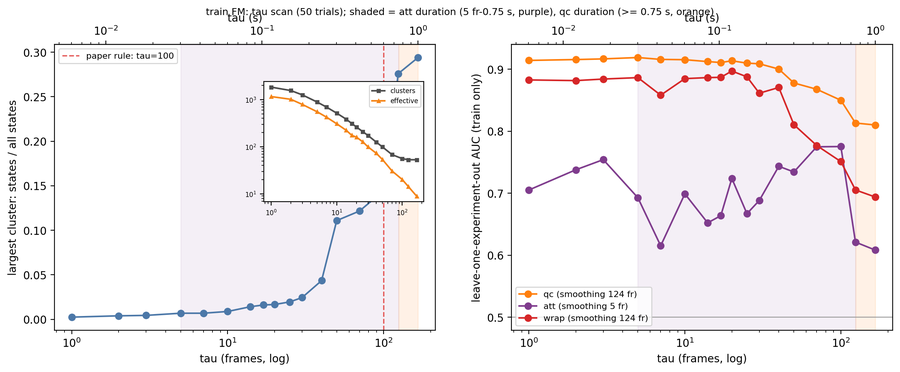


[MM] tau scan
unit  tau  tau_s  n_clusters  effective_clusters  largest_cluster_state_fraction  largest_cluster_frame_fraction  within_nodiag  loeo_auc_qc  loeo_auc_att  loeo_auc_wrap
  MM    1  0.006        1811            1195.236                           0.002                           0.005          0.026          NaN         0.921            NaN
  MM    2  0.012        1498            1035.012                           0.004                           0.005          0.088          NaN         0.919            NaN
  MM    3  0.018        1178             797.759                           0.005                           0.010          0.171          NaN         0.916            NaN
  MM    5  0.030         768             500.416                           0.008                           0.013          0.283          NaN         0.916            NaN
  MM    7  0.042         564             354.406                           0.009                           0.019          0.343        

  fig figures/03a_tau_scan__MM__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


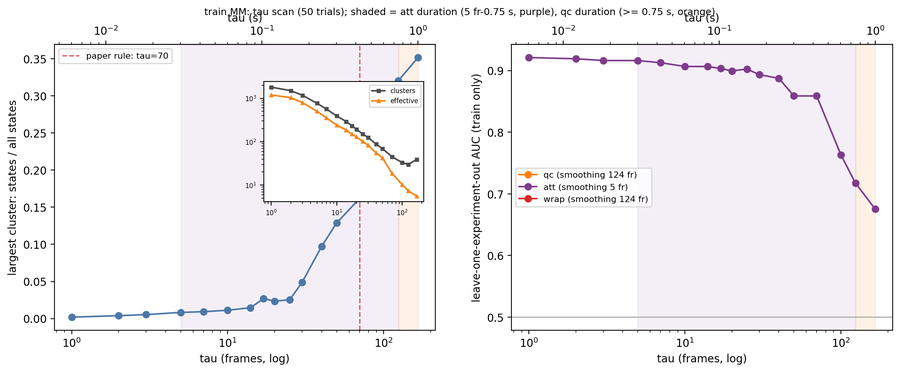

  csv data/03a_tau_choice__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.csv  rows 6
unit             reason  tau  tau_s
  FM         paper_rule  100  0.602
  FM   best_loeo_auc_qc    5  0.030
  FM  best_loeo_auc_att  100  0.602
  FM best_loeo_auc_wrap   20  0.120
  MM         paper_rule   70  0.422
  MM  best_loeo_auc_att    1  0.006


In [7]:
# Step 3a: tau scan on the training set (paper rule + leave-one-experiment-out separability).
from sklearn.metrics import roc_auc_score
L.clear_log("03a")


def loeo_scores(cl, y, exp, block, k, window):
    # Score each training experiment with cluster scores fitted on the other training experiments.
    s = np.full(len(cl), np.nan)
    for ei in np.unique(exp):
        fit = exp != ei
        cl_fit = np.where(fit, cl, -1)
        y_fit = np.where(fit, y, -1)
        sc = P4.cluster_scores(cl_fit, y_fit, k, PRIOR_FRAMES)
        okf = (y_fit >= 0) & (cl_fit >= 0)
        base = float(y_fit[okf].mean()) if okf.any() else 0.0
        m = exp == ei
        s[m] = P4.frame_scores(cl[m], sc, base)
    return P4.rolling_mean_blocks(s, block, window)


def safe_auc(y, s):
    ok = (y >= 0) & np.isfinite(s)
    if (y[ok] == 1).sum() < MIN_POS or (y[ok] == 0).sum() == 0:
        return np.nan
    return float(roc_auc_score(y[ok], s[ok]))


scan_jobs, SCAN_CTX = [], {}
for unit in UNITS:
    mic = load_micro(unit, "train")
    st, seg = mic["state"].astype(np.int64), mic["seg"]
    sf = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
    for tau in TAU_SCAN:
        counts, n_pairs = S.transition_counts(st, seg, int(tau), N_STATES)
        keep, prob = graph_input(counts, sf)
        SCAN_CTX[(unit, tau)] = (counts, keep, sf)
        scan_jobs.append(((unit, tau), prob))
t0 = time.time()
SCAN_RES = run_jobs(scan_jobs, N_TRIALS_SCAN)
print(f"tau scan: {len(scan_jobs)} Infomap runs x {N_TRIALS_SCAN} trials: {time.time() - t0:.0f} s")

scan_rows = []
for unit in UNITS:
    mic = load_micro(unit, "train")
    st = mic["state"].astype(np.int64)
    y_all = labels_for(mic)
    block = blocks_of(mic)
    targets = {c: P4.detection_target(y_all, c) for c in DETECT_CLASSES}
    for tau in TAU_SCAN:
        counts, keep, sf = SCAN_CTX[(unit, tau)]
        raw, _cl = SCAN_RES[(unit, tau)]
        lab, cover = relabel(raw, keep, sf)
        k = len(cover)
        cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
        sizes = np.bincount(lab[lab >= 0], minlength=k)
        row = {"unit": unit, "tau": tau, "tau_s": tau / FPS_NOMINAL, "n_clusters": k,
               "effective_clusters": P4.effective_clusters(cover),
               "largest_cluster_state_fraction": sizes.max() / N_STATES,
               "largest_cluster_frame_fraction": cover.max() / max(cover.sum(), 1),
               "within_nodiag": S.within_fraction(counts, lab, drop_diagonal=True)}
        for c, yc in targets.items():
            # leave-one-experiment-out needs positives in at least two training experiments
            n_exp_pos = len(np.unique(mic["exp"][yc == 1]))
            row[f"loeo_auc_{c}"] = (safe_auc(yc, loeo_scores(cl, yc, mic["exp"], block, k, SMOOTH_FRAMES[c]))
                                    if n_exp_pos >= 2 else np.nan)
        scan_rows.append(row)
SCAN = pd.DataFrame(scan_rows)
choice_rows = []
for unit in UNITS:
    d = SCAN[SCAN["unit"] == unit].reset_index(drop=True)
    L.save_csv(d, "03a", "tau_scan", unit, STATE_P, "train", verbose=False)
    print(f"\n[{unit}] tau scan\n" + d.round(3).to_string(index=False))
    picks = {"paper_rule": P4.paper_tau(d["tau"], d["largest_cluster_state_fraction"])}
    for c in DETECT_CLASSES:
        col = d[f"loeo_auc_{c}"]
        if col.notna().any():
            picks[f"best_loeo_auc_{c}"] = int(d.loc[col.idxmax(), "tau"])
    extra = set(picks.values()) if ADD_SCAN_TAUS else set()
    TAUS_FULL[unit] = sorted(set(TAUS) | extra)
    for why, t in picks.items():
        choice_rows.append({"unit": unit, "reason": why, "tau": t, "tau_s": t / FPS_NOMINAL})
    print(f"[{unit}] picks {picks} -> analysed in full: {TAUS_FULL[unit]}")
    # figure
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    ax = axes[0]
    ax.plot(d["tau"], d["largest_cluster_state_fraction"], "o-", color="#4C78A8")
    ax.set_xscale("log")
    ax.set_xlabel("tau (frames, log)")
    ax.set_ylabel("largest cluster: states / all states")
    ax.axvline(picks["paper_rule"], color="#E45756", ls="--", lw=1.2, label=f"paper rule: tau={picks['paper_rule']}")
    ax.legend(fontsize=8, loc="upper left")
    ins = ax.inset_axes([0.55, 0.45, 0.42, 0.42])
    ins.plot(d["tau"], d["n_clusters"], "s-", ms=3, color="0.3", label="clusters")
    ins.plot(d["tau"], d["effective_clusters"], "^-", ms=3, color="#F58518", label="effective")
    ins.set_xscale("log")
    ins.set_yscale("log")
    ins.legend(fontsize=6)
    ins.tick_params(labelsize=6)
    ax = axes[1]
    for c in DETECT_CLASSES:
        ax.plot(d["tau"], d[f"loeo_auc_{c}"], "o-", color=CLASS_COLOR[c], label=f"{c} (smoothing {SMOOTH_FRAMES[c]} fr)")
    ax.set_xscale("log")
    ax.set_xlabel("tau (frames, log)")
    ax.set_ylabel("leave-one-experiment-out AUC (train only)")
    ax.axhline(0.5, color="0.6", lw=0.8)
    ax.legend(fontsize=8)
    for a in axes:
        lo, hi = DURATION_S["att"]
        a.axvspan(lo * FPS_NOMINAL, hi * FPS_NOMINAL, color=CLASS_COLOR["att"], alpha=0.08)
        a.axvspan(DURATION_S["qc"][0] * FPS_NOMINAL, max(TAU_SCAN), color=CLASS_COLOR["qc"], alpha=0.10)
        sec = a.secondary_xaxis("top", functions=(lambda f: f / FPS_NOMINAL, lambda x: x * FPS_NOMINAL))
        sec.set_xlabel("tau (s)")
    fig.suptitle(f"train {unit}: tau scan ({N_TRIALS_SCAN} trials); shaded = att duration (5 fr-0.75 s, purple), "
                 f"qc duration (>= 0.75 s, orange)", fontsize=9)
    save_fig(fig, "03a", "tau_scan", unit, STATE_P, "train", show=True)
TAU_CHOICE = pd.DataFrame(choice_rows)
L.save_csv(TAU_CHOICE, "03a", "tau_choice", "all", STATE_P, "train")
L.update_params("taus_full", TAUS_FULL)
print(TAU_CHOICE.round(3).to_string(index=False))
L.log("03a", "done")

## Step 3 — 转移矩阵与 Infomap 聚类

**做什么**：对每个单元（FM、MM）、每个 τ ∈ `TAUS_FULL`（7、17 帧 + Step 3a 选出的 τ）：(t, t+τ) 两帧都有状态且在同一片段内才计数；所有实验、所有副本合并成一个矩阵；访问 ≥ `MIN_STATE_VISITS` 次的状态才进图；行归一化后作为加权有向图跑 Infomap（python-igraph，`N_TRIALS` 次）。簇按覆盖帧数降序编号（C0 最大）。**训练集**的结果是主结果；**测试集**也独立跑一次，只在 Step 4 用于对照。

**输出**（训练集）：
- `data/03_state_clusters`：状态 → 簇（Step 4、5 用它把测试集投到训练集的簇上）。
- `data/03_cluster_stats`：每簇状态数、帧数、簇内转移占比（含/不含对角线）、平均停留时间、D_xy 和 Δz 的中位数、θ_a 和 θ_b 的圆均值、来自各副本的比例（FM：FM1 vs FM2；MM：M1M2 vs M2M1）、来自 K 组的比例；MM 另有镜像配对（`partner`、`overlap`、`mutual`、`merged`）。
- `data/03_within_summary`：簇数、覆盖 95% 需要的簇数、簇内转移占比和打乱 `N_SHUFFLE` 次的参照。**按簇排序后矩阵总会显得有块，要对照打乱参照看。**
- 图：`03_cluster_matrix`（簇×簇转移，最多 `MAX_MATRIX` 个簇）、`03_state_block`（状态级块对角，稀疏散点画法）、`03_cluster_theta` 和 `03_cluster_dxy_dz`（最大 `TOP_SHOW` 个簇在 θ_a×θ_b 和 D_xy×Δz 上的占用，仿 Fig. S12，用来给簇命名）。

In [8]:
# Step 3: transitions + Infomap (train = main result; test run independently for Step 4).
L.clear_log("03")
CTX = {}
jobs = []
for set_name in SETS:
    for unit in UNITS:
        mic = load_micro(unit, set_name)
        st, seg = mic["state"].astype(np.int64), mic["seg"]
        sf_set = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
        for tau in TAUS_FULL[unit]:
            counts, n_pairs = S.transition_counts(st, seg, int(tau), N_STATES)
            keep, prob = graph_input(counts, sf_set)
            CTX[(set_name, unit, tau)] = {"counts": counts, "keep": keep, "n_pairs": n_pairs}
            jobs.append(((set_name, unit, tau), prob))
            print(f"[{set_name} {unit} tau {tau}] pairs {n_pairs}  graph nodes {len(keep)}  edges {prob.nnz}  "
                  f"diagonal share {counts.diagonal().sum() / max(counts.sum(), 1):.3f}")
t0 = time.time()
RESULTS = run_jobs(jobs, N_TRIALS)
print(f"{len(jobs)} Infomap runs x {N_TRIALS} trials: {time.time() - t0:.0f} s")

LABELS = {}   # (set, unit, tau) -> state -> cluster
for (set_name, unit, tau), (raw, codelength) in RESULTS.items():
    st = load_micro(unit, set_name)["state"].astype(np.int64)
    sf = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
    lab, cover = relabel(raw, CTX[(set_name, unit, tau)]["keep"], sf)
    LABELS[(set_name, unit, tau)] = lab
    CTX[(set_name, unit, tau)].update({"cover": cover, "codelength": codelength, "state_frames": sf})
    tab = pd.DataFrame({"state": np.arange(N_STATES), "cluster": lab, "n_frames": sf.astype(int)})
    dec = P4.decode(np.arange(N_STATES), WIDTHS)
    for j, nm in enumerate(P4.VARIABLES):
        tab[f"bin_{nm}"] = dec[:, j]
    if unit == "MM":
        tab["swap_state"] = SWAP
    L.save_csv(tab, "03", "state_clusters", unit, tau_p(tau), set_name, verbose=False)
print("state -> cluster tables written")

[train FM tau 5] pairs 2594762  graph nodes 2040  edges 32540  diagonal share 0.796
[train FM tau 7] pairs 2586504  graph nodes 2040  edges 36373  diagonal share 0.747
[train FM tau 17] pairs 2555257  graph nodes 2040  edges 50682  diagonal share 0.569
[train FM tau 20] pairs 2547700  graph nodes 2040  edges 54472  diagonal share 0.528


[train FM tau 100] pairs 2399460  graph nodes 2040  edges 108214  diagonal share 0.138
[train MM tau 1] pairs 2642618  graph nodes 2034  edges 22100  diagonal share 0.922


[train MM tau 7] pairs 2628250  graph nodes 2034  edges 44664  diagonal share 0.719
[train MM tau 17] pairs 2609858  graph nodes 2034  edges 66170  diagonal share 0.527
[train MM tau 70] pairs 2531824  graph nodes 2034  edges 129978  diagonal share 0.177


[test FM tau 5] pairs 1274180  graph nodes 2020  edges 25117  diagonal share 0.781
[test FM tau 7] pairs 1270435  graph nodes 2020  edges 27813  diagonal share 0.728
[test FM tau 17] pairs 1255895  graph nodes 2020  edges 37870  diagonal share 0.538
[test FM tau 20] pairs 1252234  graph nodes 2020  edges 40365  diagonal share 0.495
[test FM tau 100] pairs 1175899  graph nodes 2020  edges 71204  diagonal share 0.108


[test MM tau 1] pairs 1295394  graph nodes 2006  edges 18718  diagonal share 0.913
[test MM tau 7] pairs 1287398  graph nodes 2006  edges 35654  diagonal share 0.688
[test MM tau 17] pairs 1276646  graph nodes 2006  edges 51400  diagonal share 0.483
[test MM tau 70] pairs 1228698  graph nodes 2006  edges 90994  diagonal share 0.133


18 Infomap runs x 500 trials: 243 s


state -> cluster tables written



[train FM tau 5 (0.030 s)] clusters 892; 678 cover 95% of frames; largest 0.9%; within 0.852 (shuffle 0.797), no diagonal 0.275 (shuffle 0.001)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0         2           0.009         0.128                   0.294      181.123    -87.632         1.972        -2.349      0.410    0.398
       1         6           0.009         0.139                   0.532        6.074     13.578         2.271        -0.708      0.412    0.561
       2         4           0.009         0.135                   0.382       36.617      7.930         2.507         0.488      0.603    0.397
       3         4           0.008         0.136                   0.466      173.611   -103.868         1.004        -2.363      0.355    0.263
       4         2           0.008         0.159                   0.342      180.644   -101.312         1.996         2.443      

  fig figures/03_cluster_matrix__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


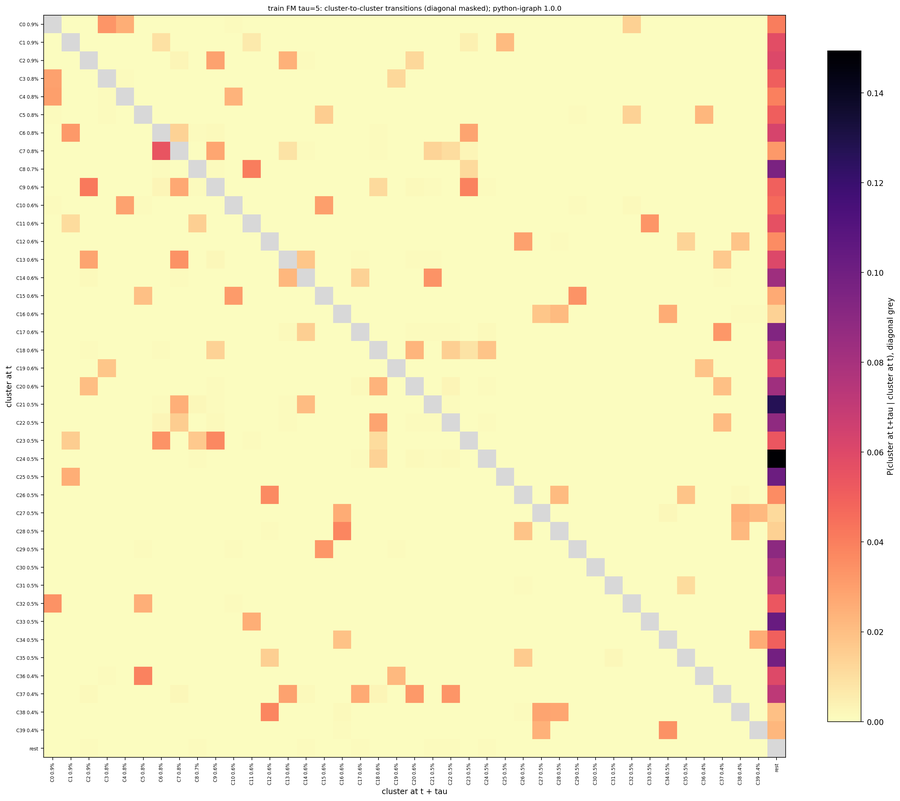

  fig figures/03_state_block__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


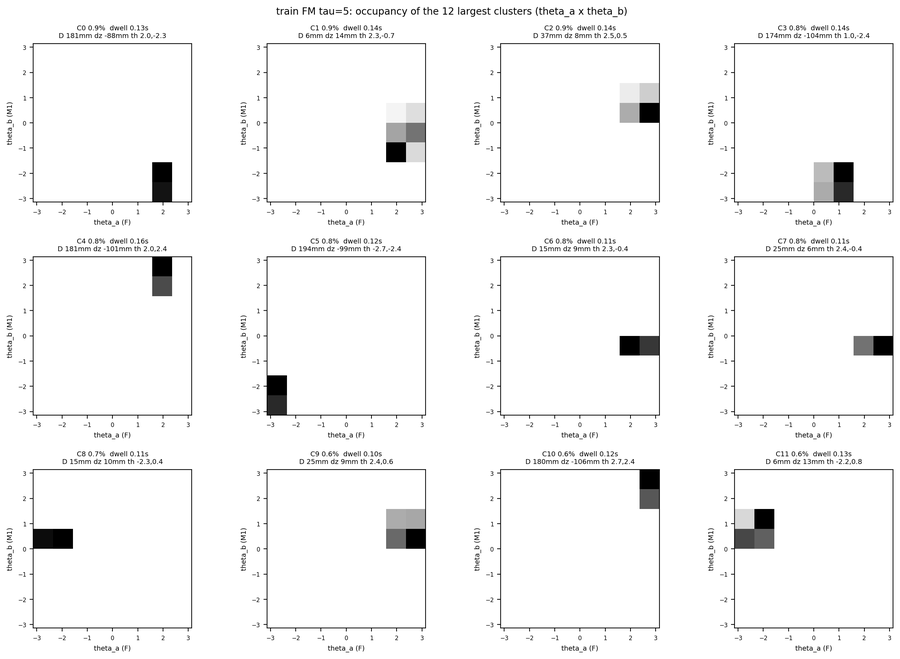

  fig figures/03_cluster_dxy_dz__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train FM tau 7 (0.042 s)] clusters 682; 517 cover 95% of frames; largest 1.9%; within 0.832 (shuffle 0.747), no diagonal 0.337 (shuffle 0.002)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0         8           0.019         0.172                   0.525       19.688      9.584        -2.357         0.599      0.489    0.520
       1         8           0.012         0.124                   0.496       20.749      9.936         2.413         0.597      0.628    0.422
       2         4           0.011         0.134                   0.363       15.309      9.681         2.286        -0.609      0.534    0.438
       3         4           0.010         0.128                   0.308       24.956      6.650         2.429        -0.546      0.564    0.399
       4         4           0.010         0.186                   0.493      183.212    -98.851        -2.401        -1.875      

  fig figures/03_cluster_matrix__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


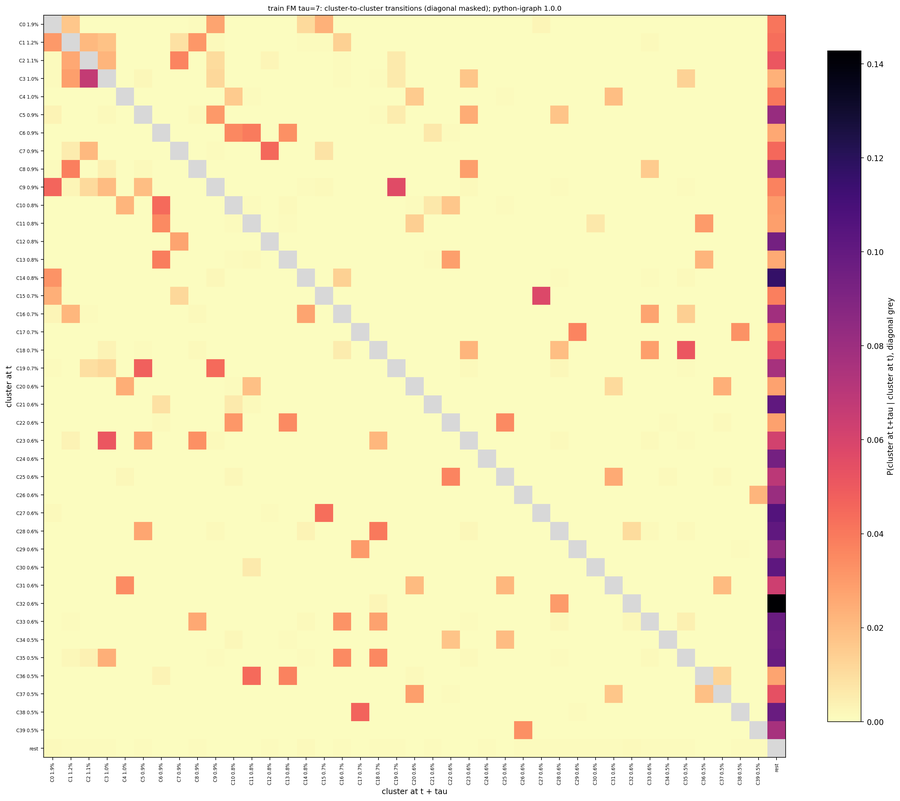

  fig figures/03_state_block__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


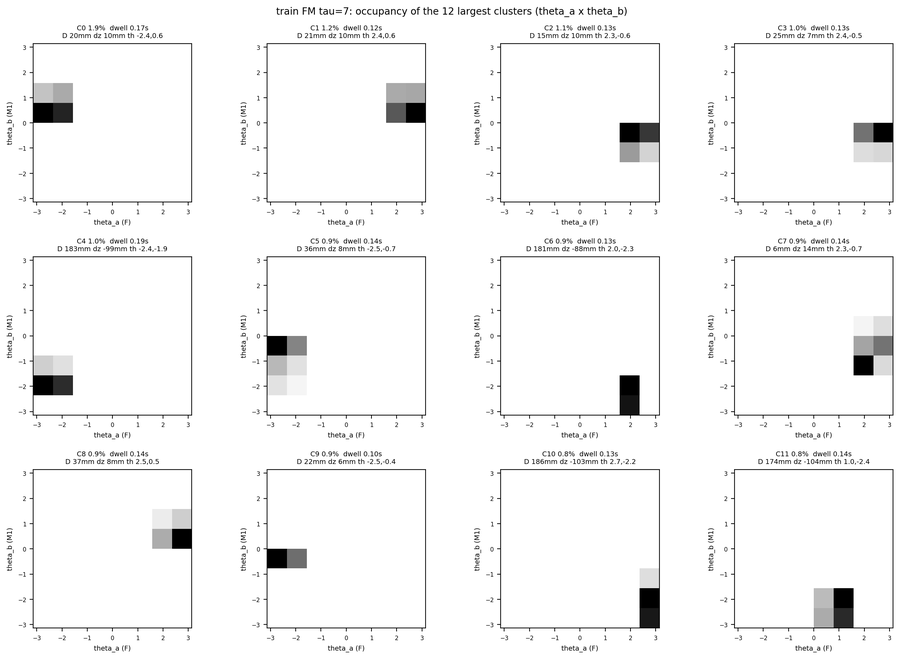

  fig figures/03_cluster_dxy_dz__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train FM tau 17 (0.102 s)] clusters 309; 224 cover 95% of frames; largest 4.0%; within 0.760 (shuffle 0.571), no diagonal 0.442 (shuffle 0.004)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0        17           0.040         0.194                   0.585       25.214      8.321         2.457         0.075      0.615    0.391
       1        10           0.030         0.231                   0.619      183.862   -102.123        -3.137        -2.912      0.419    0.317
       2        22           0.026         0.164                   0.577       26.971      8.040        -2.444        -0.811      0.581    0.408
       3        12           0.024         0.189                   0.520       17.692     10.574        -2.145         0.743      0.452    0.563
       4        21           0.020         0.184                   0.615        9.973     12.323         1.126        -1.669     

  fig figures/03_cluster_matrix__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


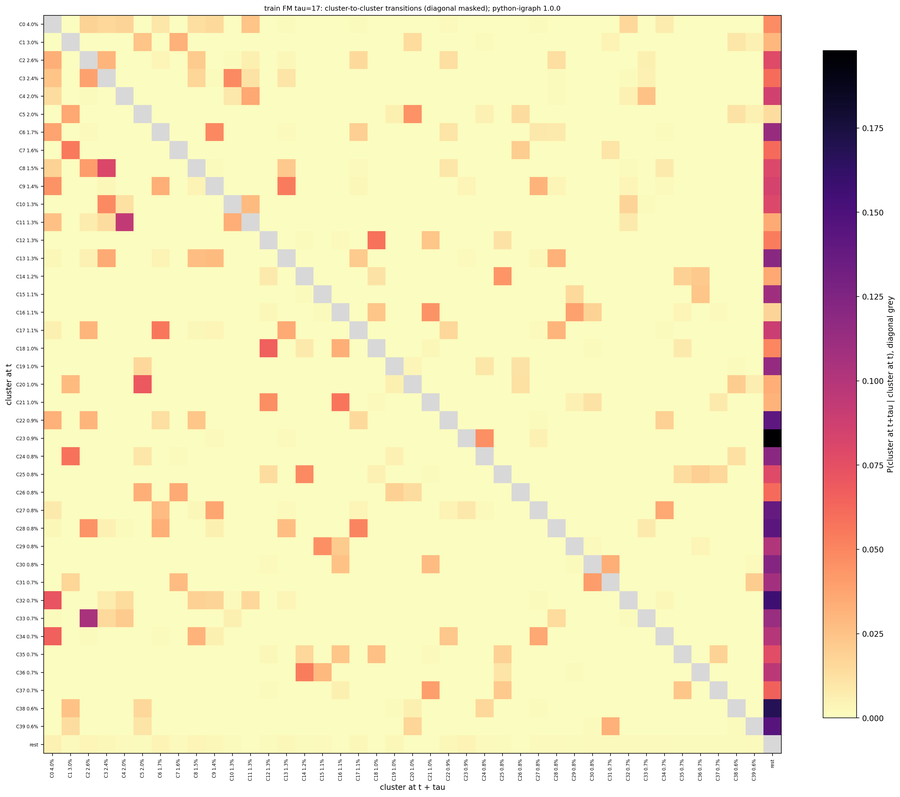

  fig figures/03_state_block__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


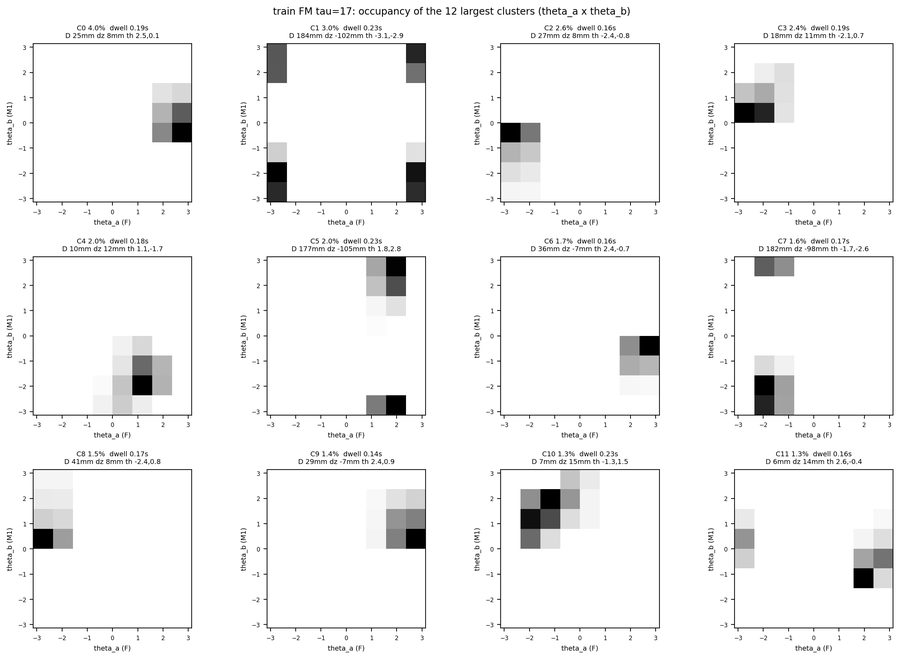

  fig figures/03_cluster_dxy_dz__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train FM tau 20 (0.120 s)] clusters 262; 189 cover 95% of frames; largest 2.7%; within 0.734 (shuffle 0.531), no diagonal 0.436 (shuffle 0.005)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0        12           0.027         0.176                   0.514       20.320      8.659         2.394         0.008      0.611    0.401
       1        20           0.026         0.160                   0.555       26.860      7.832        -2.435        -0.776      0.588    0.401
       2        12           0.021         0.174                   0.484       19.203     10.398        -2.360         0.710      0.461    0.546
       3         8           0.019         0.207                   0.569      182.168   -101.216        -2.397         2.684      0.369    0.306
       4         6           0.019         0.209                   0.542      182.438    -97.322         2.302        -2.224     

  fig figures/03_cluster_matrix__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


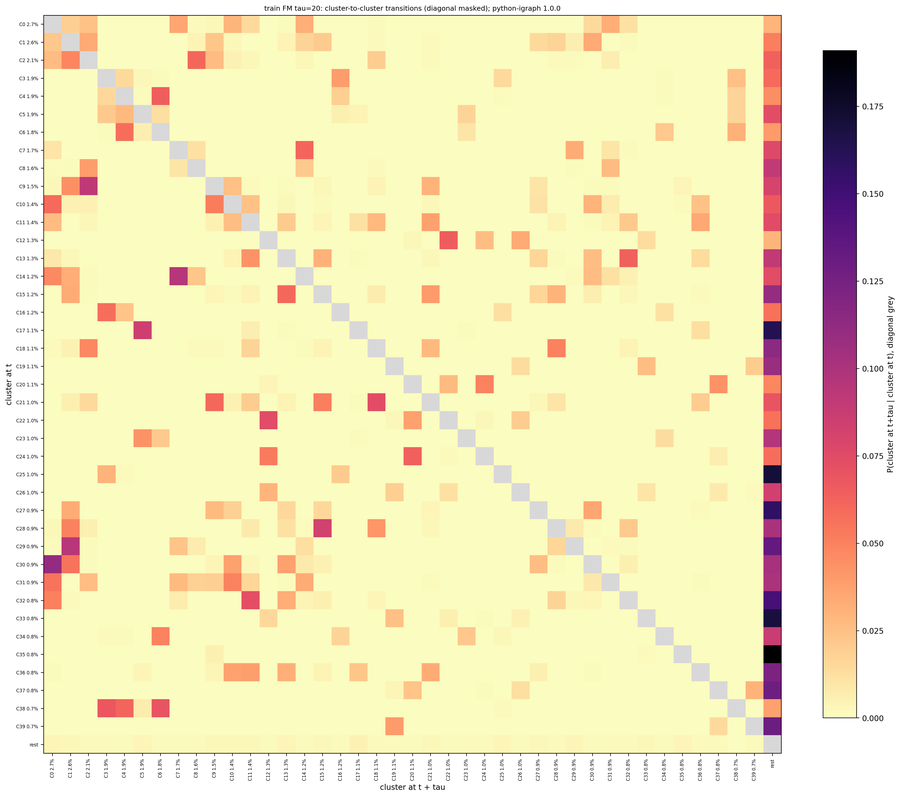

  fig figures/03_state_block__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


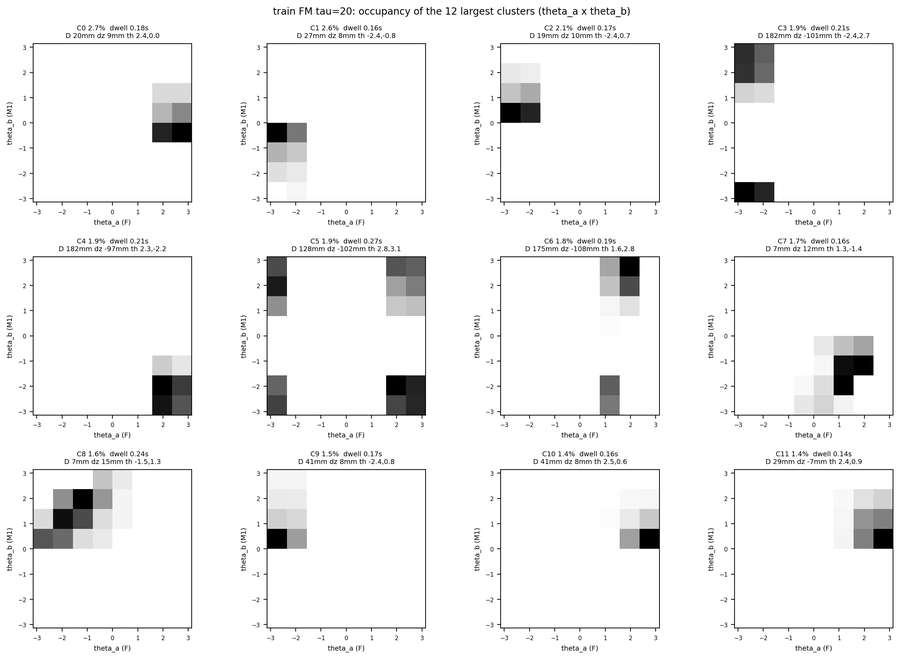

  fig figures/03_cluster_dxy_dz__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train FM tau 100 (0.602 s)] clusters 52; 26 cover 95% of frames; largest 19.3%; within 0.629 (shuffle 0.206), no diagonal 0.569 (shuffle 0.079)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0       241           0.193         0.463                   0.729       18.890     11.410        -3.061        -0.013      0.443    0.543
       1       130           0.126         1.044                   0.753      175.434     39.369        -3.139        -3.023      0.663    0.655
       2       108           0.100         0.368                   0.687      153.283   -101.064         1.739        -2.843      0.413    0.305
       3       205           0.091         0.227                   0.519       30.136     -9.120         2.973         0.059      0.498    0.495
       4       300           0.076         0.688                   0.665       34.111     63.204        -2.943        -2.826     

  fig figures/03_cluster_matrix__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


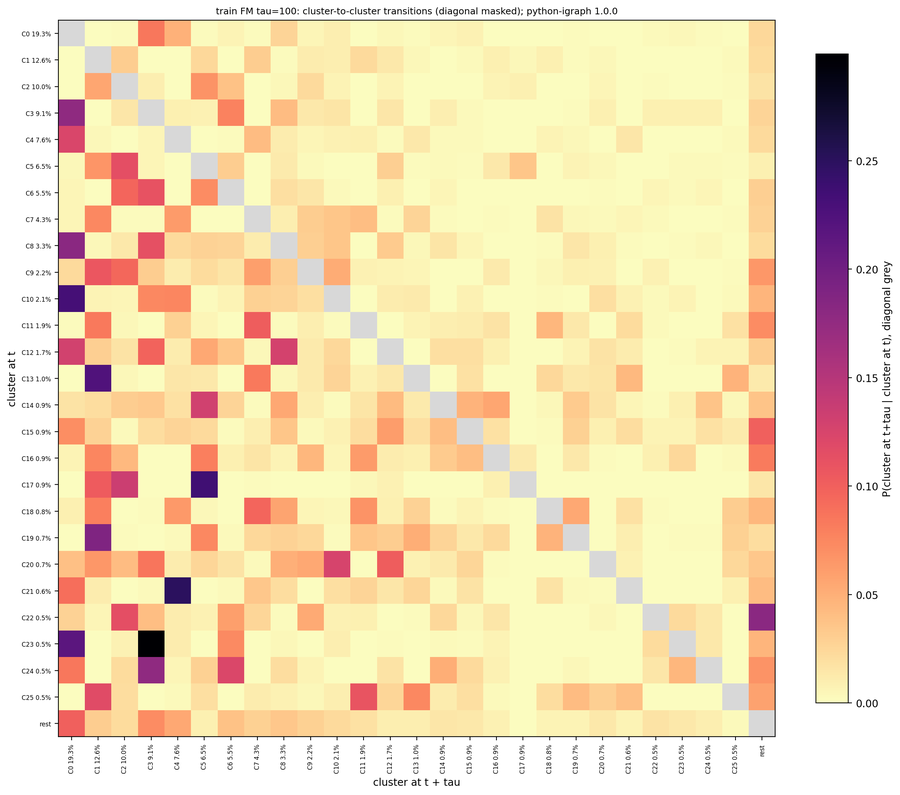

  fig figures/03_state_block__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


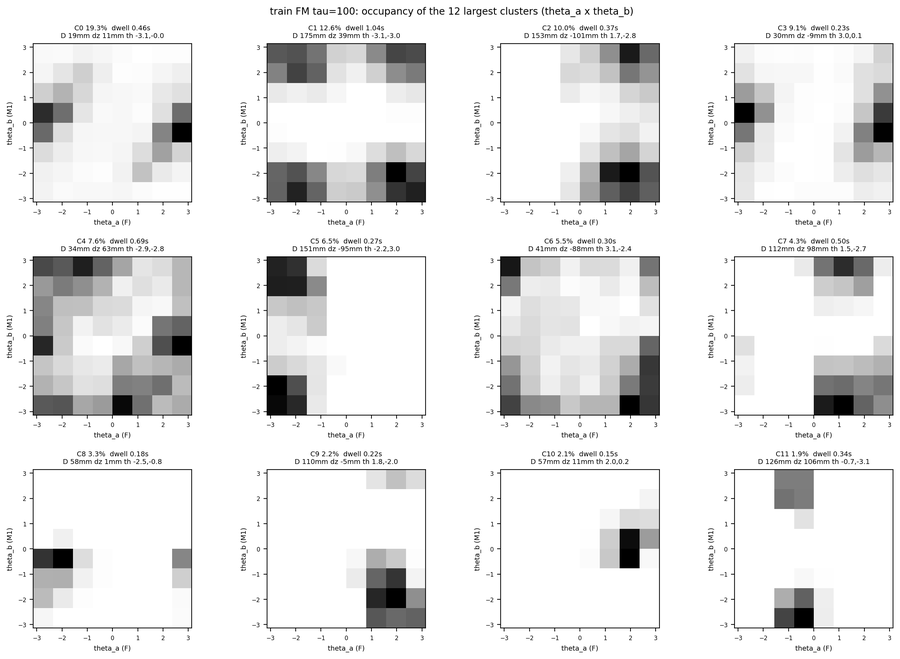

  fig figures/03_cluster_dxy_dz__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train MM tau 1 (0.006 s)] clusters 1811; 1384 cover 95% of frames; largest 0.5%; within 0.924 (shuffle 0.922), no diagonal 0.026 (shuffle 0.000)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_M1M2  share_K  partner  overlap  mutual
       0         1           0.005         0.127                     0.0      190.913   -104.290        -1.911        -1.967       0.587    0.335        1      1.0    True
       1         1           0.005         0.127                     0.0      190.913    104.290        -1.967        -1.911       0.413    0.335        0      1.0    True
       2         1           0.005         0.142                     0.0      177.995    -86.409         1.990        -1.978       0.735    0.457        3      1.0    True
       3         1           0.005         0.142                     0.0      177.995     86.409        -1.978         1.990       0.265    0.457        2      1.0  

  fig figures/03_cluster_matrix__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


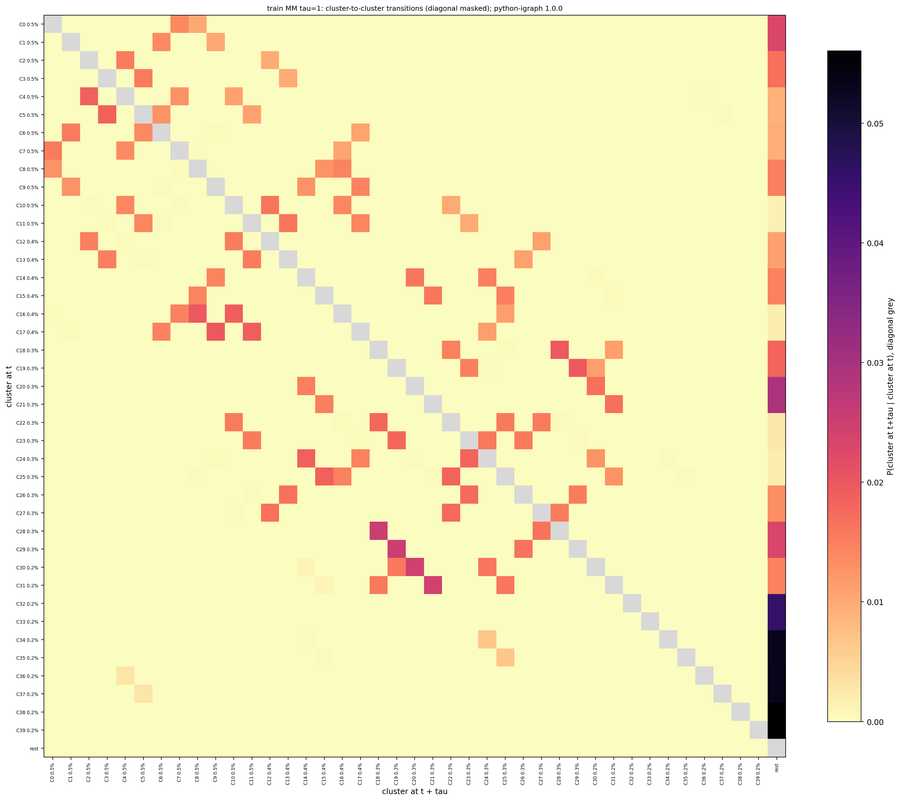

  fig figures/03_state_block__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


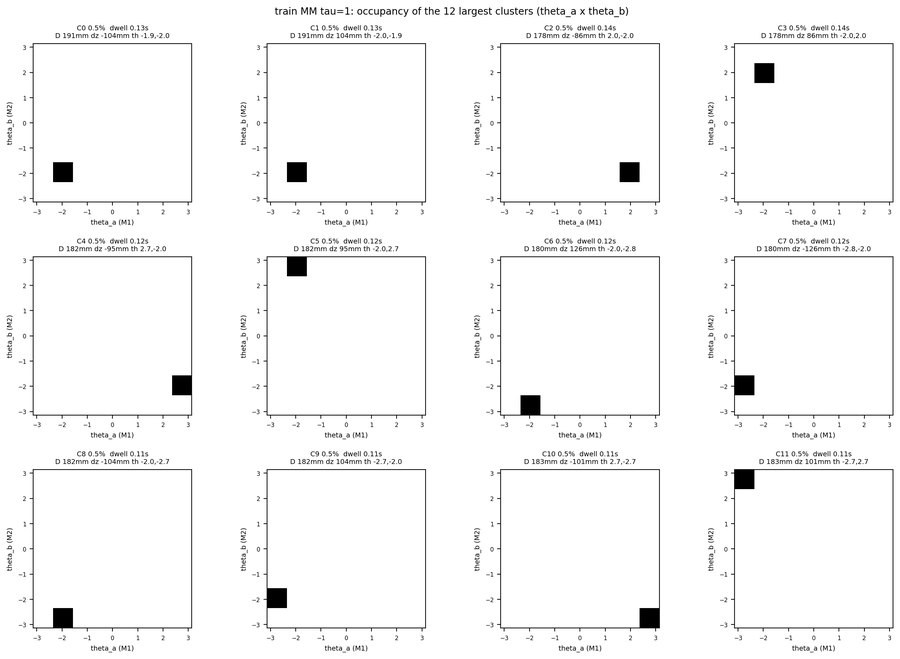

  fig figures/03_cluster_dxy_dz__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train MM tau 7 (0.042 s)] clusters 559; 424 cover 95% of frames; largest 1.9%; within 0.814 (shuffle 0.719), no diagonal 0.341 (shuffle 0.002)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_M1M2  share_K  partner  overlap  mutual
       0         4           0.019         0.276                   0.537      181.098     94.445        -2.336         2.363       0.213    0.515        6    0.542    True
       1         6           0.019         0.239                   0.560      179.695     95.311        -3.109        -2.143       0.247    0.506        2    0.460    True
       2         6           0.016         0.250                   0.599      179.456    -97.182        -2.109         2.397       0.730    0.547        1    0.550    True
       3         4           0.012         0.202                   0.520      181.165   -102.059         2.411         2.372       0.786    0.551        4    1.000    

  fig figures/03_cluster_matrix__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


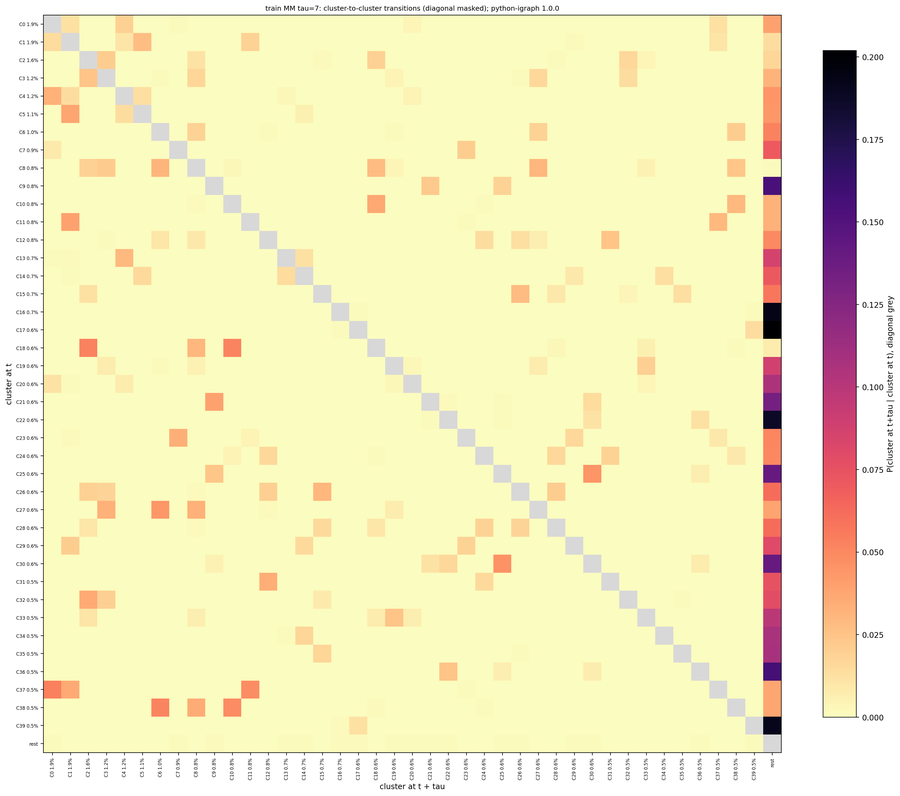

  fig figures/03_state_block__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


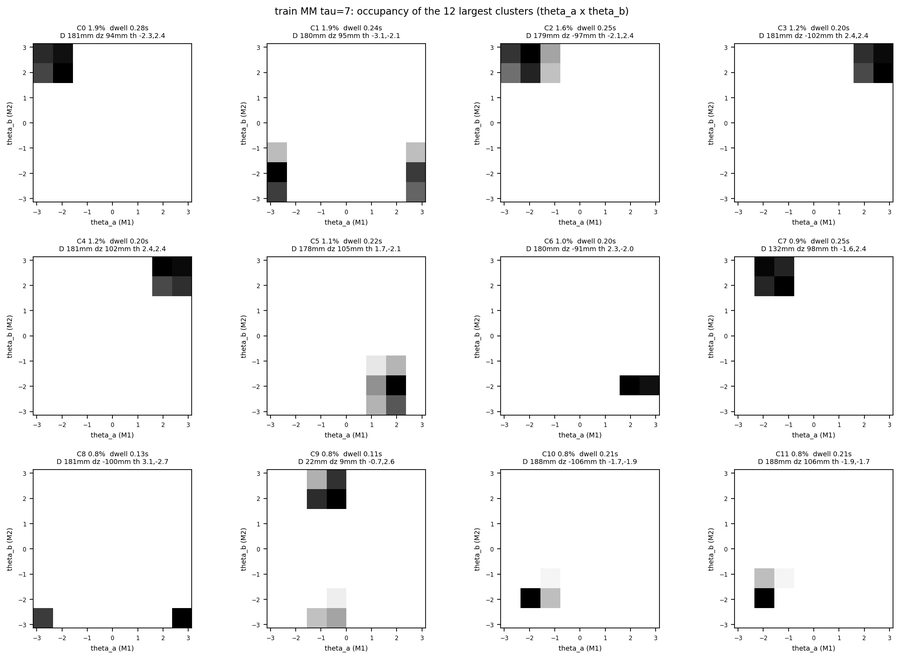

  fig figures/03_cluster_dxy_dz__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train MM tau 17 (0.102 s)] clusters 233; 173 cover 95% of frames; largest 3.1%; within 0.730 (shuffle 0.530), no diagonal 0.428 (shuffle 0.006)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_M1M2  share_K  partner  overlap  mutual
       0         8           0.031         0.346                   0.604      180.399     99.445        -2.340         2.586       0.197    0.506        1    0.901    True
       1         6           0.028         0.310                   0.563      180.592    -98.814         2.717        -2.333       0.800    0.517        0    1.000    True
       2         9           0.019         0.297                   0.608      178.574     99.860         2.196        -2.119       0.272    0.556        3    1.000    True
       3         9           0.019         0.297                   0.608      178.574    -99.860        -2.119         2.196       0.728    0.556        2    1.000   

  fig figures/03_cluster_matrix__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


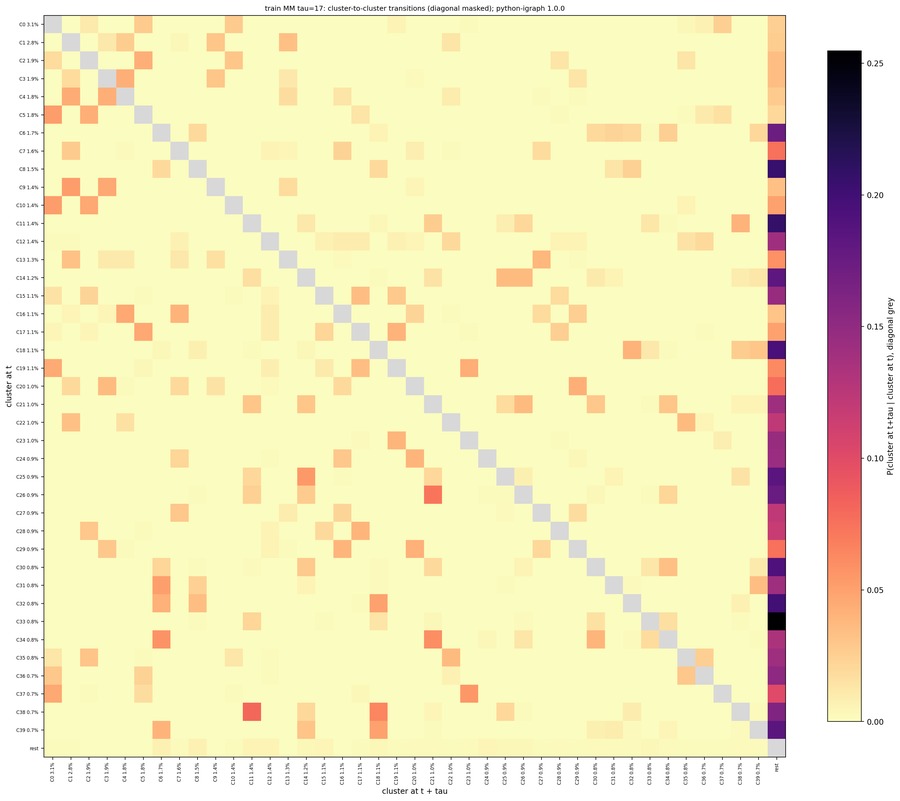

  fig figures/03_state_block__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


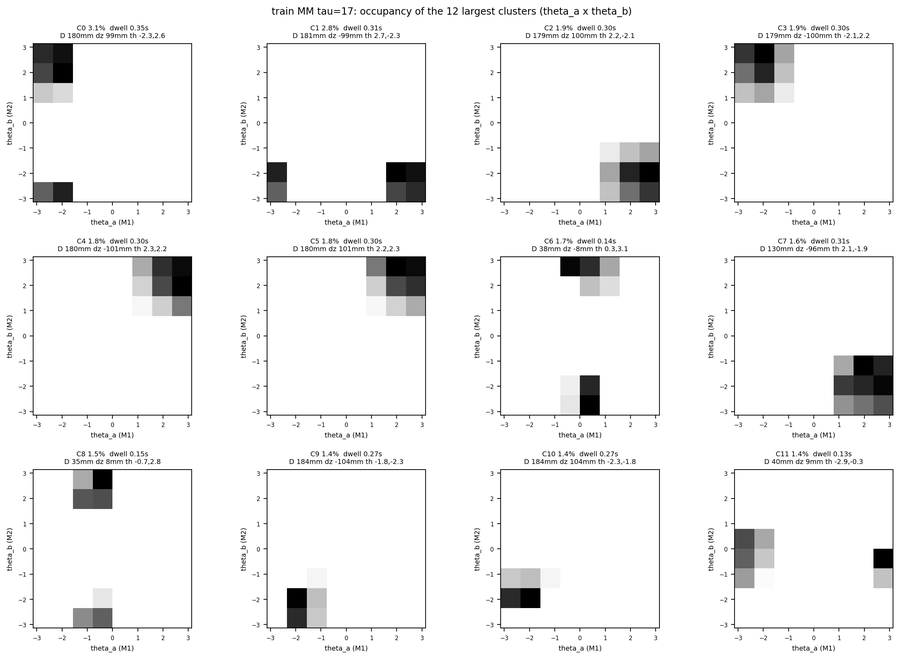

  fig figures/03_cluster_dxy_dz__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png



[train MM tau 70 (0.422 s)] clusters 45; 23 cover 95% of frames; largest 17.2%; within 0.640 (shuffle 0.236), no diagonal 0.562 (shuffle 0.071)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_M1M2  share_K  partner  overlap  mutual
       0       121           0.172         1.967                   0.827      157.250    -99.113        -3.126        -2.885       0.759    0.537        1    0.992    True
       1       116           0.171         2.012                   0.826      156.948     99.330        -2.894        -3.121       0.241    0.538        0    0.999    True
       2       331           0.077         0.491                   0.651       46.954    -71.471        -2.786         3.129       0.632    0.510        3    0.804    True
       3       299           0.063         0.393                   0.626       40.049     67.706         2.905        -2.394       0.375    0.504        2    0.986    

  fig figures/03_cluster_matrix__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


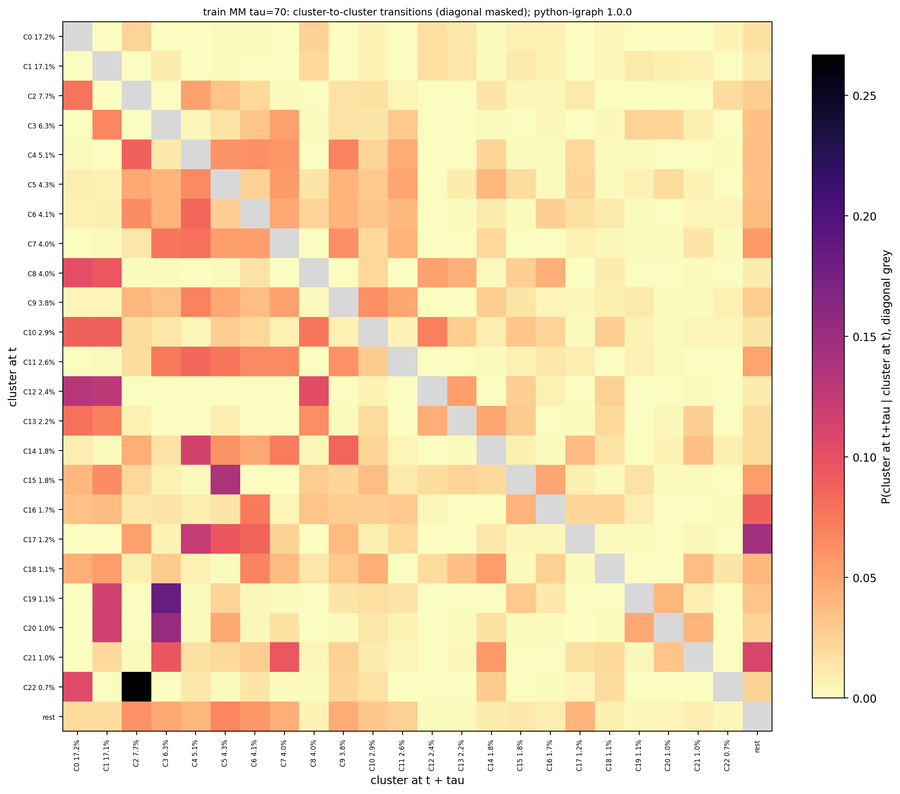

  fig figures/03_state_block__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


  fig figures/03_cluster_theta__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png


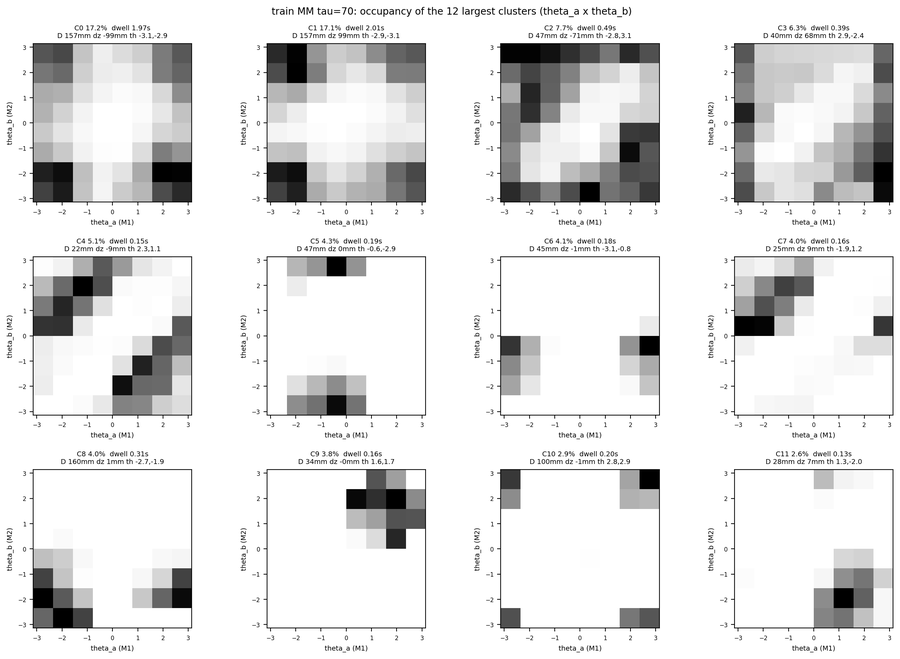

  fig figures/03_cluster_dxy_dz__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__train.png
  csv data/03_within_summary__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__train.csv  rows 9
unit  tau  tau_s  n_clusters  n_clusters_95pct  largest_cluster_frame_fraction  effective_clusters  median_states_per_cluster  occupied_states  valid_pairs  within  within_nodiag  shuffle_within_mean  shuffle_within_nodiag_mean  codelength  mirror_mutual_pairs  mirror_self_symmetric  mirror_frame_fraction_mutual
  FM    5  0.030         892               678                           0.009             552.421                        2.0             2040      2594762   0.852          0.275                0.797                       0.001       4.954                  NaN                    NaN                           NaN
  FM    7  0.042         682               517                           0.019             411.792                        2.0             2040      2586504   0.832          0.337                

In [9]:
# Step 3 (continued): statistics and figures for the training-set clustering.
CMAP_W = plt.get_cmap("viridis").copy()
CMAP_W.set_bad("white")
STATS = {}
SUMMARY = []
for unit in UNITS:
    mic = load_micro(unit, "train")
    st = mic["state"].astype(np.int64)
    seg, vals, cop, exp = mic["seg"], mic["vals"].astype(np.float64), mic["copy"], mic["exp"]
    exp_names = [str(x) for x in mic["exp_names"]]
    copy_names = [str(x) for x in mic["copy_names"]]
    is_k = np.array([exp_group(e).startswith("K") for e in exp_names])[exp]
    for tau in TAUS_FULL[unit]:
        ctx = CTX[("train", unit, tau)]
        lab, cover, counts, keep = LABELS[("train", unit, tau)], ctx["cover"], ctx["counts"], ctx["keep"]
        fps = float(load_exp(TRAIN_EXPERIMENTS[0])["fps"])
        tp = tau_p(tau)
        k = len(cover)
        cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
        n_valid = int((st >= 0).sum())
        cum = np.cumsum(cover) / n_valid
        n_sel = int(np.searchsorted(cum, COVERAGE) + 1)
        n_st = np.bincount(lab[lab >= 0], minlength=k)
        # per-cluster statistics from frame-level values
        m = cl >= 0
        df = pd.DataFrame({"cluster": cl[m], "D_xy": vals[m, 0], "dz": vals[m, 1],
                           "sa": np.sin(vals[m, 2]), "ca": np.cos(vals[m, 2]),
                           "sb": np.sin(vals[m, 3]), "cb": np.cos(vals[m, 3]),
                           "copy0": cop[m] == 0, "K": is_k[m]})
        agg = df.groupby("cluster").agg(D_xy_median=("D_xy", "median"),
                                        D_xy_p10=("D_xy", lambda x: np.percentile(x, 10)),
                                        D_xy_p90=("D_xy", lambda x: np.percentile(x, 90)),
                                        dz_median=("dz", "median"), sa=("sa", "sum"), ca=("ca", "sum"),
                                        sb=("sb", "sum"), cb=("cb", "sum"),
                                        share_copy0=("copy0", "mean"), share_K=("K", "mean")).reindex(np.arange(k))
        w_d = S.per_cluster_within(counts, lab)
        w_n = S.per_cluster_within(counts, lab, drop_diagonal=True)
        dw = S.dwell_runs(cl, seg).groupby("cluster")["length"].agg(["mean", "count"]).reindex(np.arange(k))
        stats = pd.DataFrame({
            "cluster": np.arange(k), "n_states": n_st, "n_frames": cover.astype(int),
            "frame_fraction": cover / n_valid, "selected": np.arange(k) < n_sel,
            "within_fraction": w_d["within_fraction"].to_numpy(),
            "within_fraction_nodiag": w_n["within_fraction"].to_numpy(),
            "mean_dwell_s": dw["mean"].to_numpy() / fps, "n_dwell_runs": dw["count"].fillna(0).astype(int).to_numpy(),
            "D_xy_median": agg["D_xy_median"].to_numpy(), "D_xy_p10": agg["D_xy_p10"].to_numpy(),
            "D_xy_p90": agg["D_xy_p90"].to_numpy(), "dz_median": agg["dz_median"].to_numpy(),
            "theta_a_mean": np.arctan2(agg["sa"], agg["ca"]).to_numpy(),
            "theta_b_mean": np.arctan2(agg["sb"], agg["cb"]).to_numpy(),
            f"share_{copy_names[0]}": agg["share_copy0"].to_numpy(), "share_K": agg["share_K"].to_numpy()})
        if unit == "MM":
            mir = P4.mirror_partners(lab, SWAP, ctx["state_frames"])
            stats = stats.merge(mir, on="cluster", how="left")
        STATS[(unit, tau)] = stats
        L.save_csv(stats, "03", "cluster_stats", unit, tp, "train", verbose=False)
        # within-cluster share vs shuffled labels
        rng = np.random.default_rng(INFOMAP_SEED)
        sh, sh_nd = [], []
        for _ in range(N_SHUFFLE):
            perm = lab.copy()
            perm[keep] = rng.permutation(lab[keep])
            sh.append(S.within_fraction(counts, perm))
            sh_nd.append(S.within_fraction(counts, perm, drop_diagonal=True))
        row = {"unit": unit, "tau": tau, "tau_s": tau / fps, "n_clusters": k, "n_clusters_95pct": n_sel,
               "largest_cluster_frame_fraction": cover[0] / n_valid, "effective_clusters": P4.effective_clusters(cover), "median_states_per_cluster": float(np.median(n_st)),
               "occupied_states": len(keep), "valid_pairs": ctx["n_pairs"],
               "within": S.within_fraction(counts, lab), "within_nodiag": S.within_fraction(counts, lab, drop_diagonal=True),
               "shuffle_within_mean": np.mean(sh), "shuffle_within_nodiag_mean": np.mean(sh_nd),
               "codelength": ctx["codelength"]}
        if unit == "MM":
            row["mirror_mutual_pairs"] = int((stats["mutual"] & ~stats["self_symmetric"]).sum() // 2)
            row["mirror_self_symmetric"] = int(stats["self_symmetric"].sum())
            row["mirror_frame_fraction_mutual"] = float(stats.loc[stats["mutual"], "frame_fraction"].sum())
        SUMMARY.append(row)
        print(f"\n[train {unit} tau {tau} ({tau / fps:.3f} s)] clusters {k}; {n_sel} cover {100 * COVERAGE:.0f}% of frames; "
              f"largest {100 * cover[0] / n_valid:.1f}%; within {row['within']:.3f} (shuffle {row['shuffle_within_mean']:.3f}), "
              f"no diagonal {row['within_nodiag']:.3f} (shuffle {row['shuffle_within_nodiag_mean']:.3f})")
        cols = ["cluster", "n_states", "frame_fraction", "mean_dwell_s", "within_fraction_nodiag", "D_xy_median",
                "dz_median", "theta_a_mean", "theta_b_mean", f"share_{copy_names[0]}", "share_K"]
        if unit == "MM":
            cols += ["partner", "overlap", "mutual"]
        print(stats.head(TOP_SHOW)[cols].round(3).to_string(index=False))

        # (a) cluster x cluster matrix
        n_show = min(n_sel, MAX_MATRIX, k)
        disp = np.where(lab >= 0, np.minimum(lab, n_show), -1)
        coo = counts.tocoo()
        okc = (disp[coo.row] >= 0) & (disp[coo.col] >= 0)
        nn = n_show + int(k > n_show)
        C = np.zeros((nn, nn))
        np.add.at(C, (disp[coo.row[okc]], disp[coo.col[okc]]), coo.data[okc])
        Pc = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
        labels = [f"C{c} {100 * cover[c] / n_valid:.1f}%" for c in range(n_show)] + (["rest"] if k > n_show else [])
        show = np.ma.array(Pc, mask=np.eye(nn, dtype=bool))
        fig, ax = plt.subplots(figsize=(min(20, 0.38 * nn + 4), min(18, 0.34 * nn + 3.5)))
        cm = plt.get_cmap("magma_r").copy()
        cm.set_bad("0.85")
        im = ax.imshow(show, cmap=cm, vmin=0, vmax=max(float(show.max()), 1e-6), interpolation="nearest")
        ax.set_xticks(np.arange(nn), labels, rotation=90, fontsize=6)
        ax.set_yticks(np.arange(nn), labels, fontsize=6)
        ax.set_xlabel("cluster at t + tau")
        ax.set_ylabel("cluster at t")
        fig.colorbar(im, ax=ax, fraction=0.04, label="P(cluster at t+tau | cluster at t), diagonal grey")
        ax.set_title(f"train {unit} tau={tau}: cluster-to-cluster transitions (diagonal masked); {BACKEND_TAG}", fontsize=9)
        save_fig(fig, "03", "cluster_matrix", unit, tp, "train", show=True)

        # (b) state-level block view (sparse scatter; states ordered by cluster)
        sel_states = np.flatnonzero((lab >= 0) & (lab < n_show))
        order = sel_states[np.lexsort((sel_states, lab[sel_states]))]
        pos = np.full(N_STATES, -1)
        pos[order] = np.arange(len(order))
        pr = S.row_normalize(counts).tocoo()
        okp = (pos[pr.row] >= 0) & (pos[pr.col] >= 0)
        fig, ax = plt.subplots(figsize=(10, 10))
        sc = ax.scatter(pos[pr.col[okp]], pos[pr.row[okp]], c=np.log10(pr.data[okp]), s=0.3, marker="s",
                        cmap="viridis", vmin=-3, vmax=0, linewidths=0)
        bounds = np.flatnonzero(np.diff(lab[order]) != 0) + 0.5
        for b in bounds:
            ax.axhline(b, color="0.7", lw=0.2)
            ax.axvline(b, color="0.7", lw=0.2)
        ax.set_xlim(-0.5, len(order) - 0.5)
        ax.set_ylim(len(order) - 0.5, -0.5)
        ax.set_xlabel("state at t + tau (ordered by cluster)")
        ax.set_ylabel("state at t")
        fig.colorbar(sc, ax=ax, fraction=0.04, label="log10 P(s_t+tau | s_t)")
        ax.set_title(f"train {unit} tau={tau}: {len(order)} states of the {n_show} largest clusters", fontsize=9)
        save_fig(fig, "03", "state_block", unit, tp, "train")

        # (c) cluster maps: theta_a x theta_b and D_xy x dz occupancy of the largest clusters
        dec = P4.decode(np.arange(N_STATES), WIDTHS)
        sf = ctx["state_frames"]
        ncol = 4
        nrow = int(np.ceil(min(TOP_SHOW, k) / ncol))
        for which in ("theta", "dxy_dz"):
            fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.2 * nrow), squeeze=False)
            for c in range(nrow * ncol):
                ax = axes[c // ncol, c % ncol]
                if c >= min(TOP_SHOW, k):
                    ax.axis("off")
                    continue
                stc = np.flatnonzero(lab == c)
                if which == "theta":
                    H = np.zeros((WIDTHS[2], WIDTHS[3]))
                    np.add.at(H, (dec[stc, 2], dec[stc, 3]), sf[stc])
                    ax.imshow(H.T, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], cmap="Greys")
                    ax.set_xlabel(f"theta_a ({UNITS[unit][0][0]})", fontsize=7)
                    ax.set_ylabel(f"theta_b ({UNITS[unit][0][1]})", fontsize=7)
                else:
                    H = np.zeros((WIDTHS[0], WIDTHS[1]))
                    np.add.at(H, (dec[stc, 0], dec[stc, 1]), sf[stc])
                    ax.imshow(H.T, origin="lower", aspect="auto", cmap="Greys")
                    ax.set_xticks(np.arange(WIDTHS[0]), [f"{e:.0f}" for e in EDGES[0][:-1]], fontsize=5, rotation=90)
                    ax.set_yticks(np.arange(WIDTHS[1]), [f"{e:.0f}" for e in EDGES[1][:-1]], fontsize=5)
                    ax.set_xlabel("D_xy bin lower edge (mm)", fontsize=7)
                    ax.set_ylabel("dz bin lower edge (mm)", fontsize=7)
                r = stats.iloc[c]
                ax.set_title(f"C{c} {100 * r.frame_fraction:.1f}%  dwell {r.mean_dwell_s:.2f}s\n"
                             f"D {r.D_xy_median:.0f}mm dz {r.dz_median:.0f}mm "
                             f"th {r.theta_a_mean:.1f},{r.theta_b_mean:.1f}", fontsize=7)
                ax.tick_params(labelsize=6)
            fig.suptitle(f"train {unit} tau={tau}: occupancy of the {min(TOP_SHOW, k)} largest clusters "
                         f"({'theta_a x theta_b' if which == 'theta' else 'D_xy x dz'})", fontsize=10)
            fig.tight_layout()
            save_fig(fig, "03", f"cluster_{which}", unit, tp, "train", show=(which == "theta"))
SUMMARY_T = pd.DataFrame(SUMMARY)
L.save_csv(SUMMARY_T, "03", "within_summary", "all", STATE_P, "train")
print(SUMMARY_T.round(3).to_string(index=False))
L.log("03", "done")

## Step 4 — 测试集泛化，以及每个实验、每个配对的簇使用频率

**做什么**（每个单元、每个 τ）：
1. 测试集的每帧状态用**训练集**的状态→簇表查簇。打印测试帧中有簇的比例（状态在训练图里出现过）。
2. 簇占用分布：训练 vs 测试的 Jensen-Shannon 距离（整体，以及按副本 FM1/FM2/M1M2/M2M1）；散点图 `04_occupancy_train_test`。
3. 测试集独立 Infomap（Step 3 已跑）与"训练簇投影"在测试帧上的一致性：ARI、NMI。
4. 6 个实验 × 每个副本落在最大 `TOP_SHOW` 个簇的比例：`data/04_usage`、热图 `04_usage`。这是之后比较 F-M1 vs F-M2、K vs P、第 1/2/3 次实验的基础。

**输出**：`data/04_generalization__all__…__test.csv`、`data/04_usage__<unit>__<tau…>__all.csv`、图 `04_occupancy_train_test`、`04_usage`。

  fig figures/04_occupancy_train_test__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


  fig figures/04_occupancy_train_test__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


  fig figures/04_occupancy_train_test__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


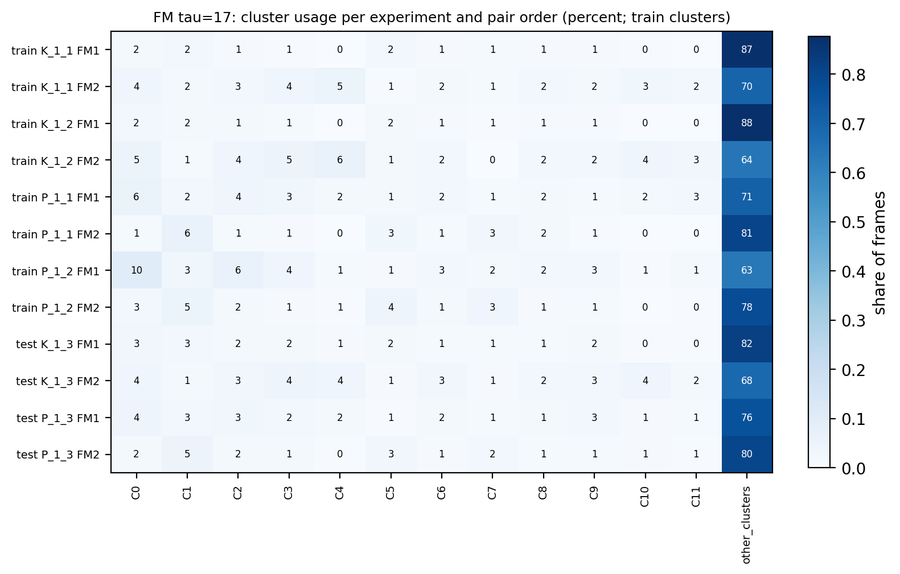

  fig figures/04_occupancy_train_test__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


  fig figures/04_occupancy_train_test__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


  fig figures/04_occupancy_train_test__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


  fig figures/04_occupancy_train_test__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


  fig figures/04_occupancy_train_test__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png


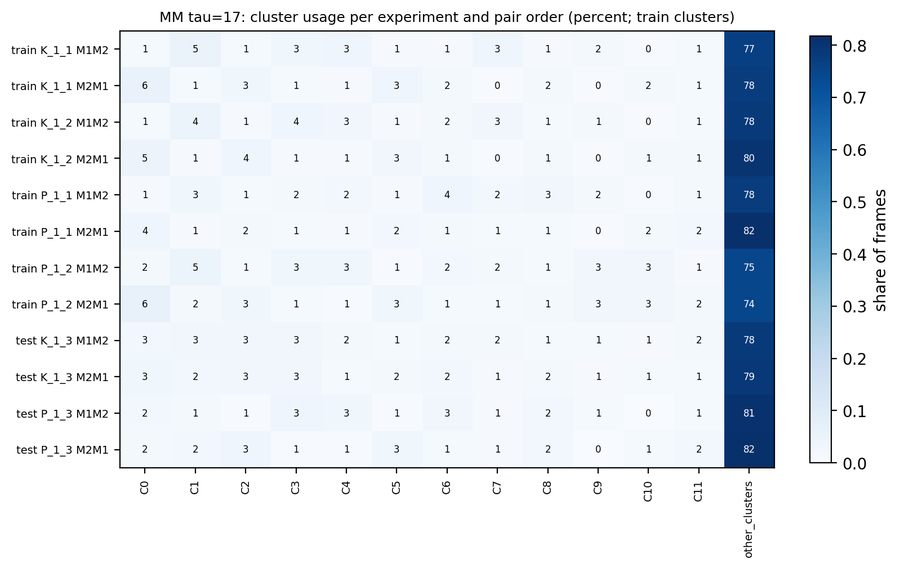

  fig figures/04_occupancy_train_test__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/04_usage__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__all.png
  csv data/04_generalization__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__test.csv  rows 9
                                             0        1        2        3        4        5        6        7        8
unit                                        FM       FM       FM       FM       FM       MM       MM       MM       MM
tau                                          5        7       17       20      100        1        7       17       70
test_frames_with_state                 1287583  1287583  1287583  1287583  1287583  1297260  1297260  1297260  1297260
test_frames_in_train_clusters_percent   99.974   99.974   99.974   99.974   99.974   99.968   99.968   99.968   99.968
js_train_test                             0.18    0.171    0.142    0.138    0.087    0.178    0.138    0.108     0.07
test_own_clusters                          805      631      301      261       83     1699      527      223       48
t

In [10]:
# Step 4: test-set generalisation and per-experiment cluster usage.
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
L.clear_log("04")
GEN = []
for unit in UNITS:
    for tau in TAUS_FULL[unit]:
        tp = tau_p(tau)
        lab_tr = LABELS[("train", unit, tau)]
        lab_te = LABELS[("test", unit, tau)]
        k = int(lab_tr.max()) + 1
        tr = load_micro(unit, "train")
        te = load_micro(unit, "test")
        st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
        cl_tr = np.where(st_tr >= 0, lab_tr[np.clip(st_tr, 0, None)], -1)
        cl_te = np.where(st_te >= 0, lab_tr[np.clip(st_te, 0, None)], -1)
        own_te = np.where(st_te >= 0, lab_te[np.clip(st_te, 0, None)], -1)
        has = st_te >= 0
        occ_tr = np.bincount(cl_tr[cl_tr >= 0], minlength=k)
        occ_te = np.bincount(cl_te[cl_te >= 0], minlength=k)
        both = (cl_te >= 0) & (own_te >= 0)
        row = {"unit": unit, "tau": tau, "test_frames_with_state": int(has.sum()),
               "test_frames_in_train_clusters_percent": 100.0 * (cl_te >= 0).sum() / max(has.sum(), 1),
               "js_train_test": S.js_distance(occ_tr, occ_te),
               "test_own_clusters": int(lab_te.max()) + 1, "train_clusters": k,
               "ari_train_map_vs_test_infomap": adjusted_rand_score(cl_te[both], own_te[both]),
               "nmi_train_map_vs_test_infomap": normalized_mutual_info_score(cl_te[both], own_te[both])}
        for ci, cp in enumerate(COPIES[unit]):
            a = np.bincount(cl_tr[(cl_tr >= 0) & (tr["copy"] == ci)], minlength=k)
            b = np.bincount(cl_te[(cl_te >= 0) & (te["copy"] == ci)], minlength=k)
            row[f"js_{cp}"] = S.js_distance(a, b)
        GEN.append(row)
        # occupancy scatter
        fig, ax = plt.subplots(figsize=(5.5, 5.2))
        p_tr, p_te = occ_tr / occ_tr.sum(), occ_te / max(occ_te.sum(), 1)
        ax.loglog(p_tr + 1e-7, p_te + 1e-7, ".", ms=3, alpha=0.6)
        for c in range(min(TOP_SHOW, k)):
            ax.annotate(f"C{c}", (p_tr[c], p_te[c] + 1e-7), fontsize=6)
        lim = [1e-7, 1]
        ax.plot(lim, lim, "k:", lw=0.8)
        ax.set_xlabel("frame share in train")
        ax.set_ylabel("frame share in test (train clusters)")
        ax.set_title(f"{unit} tau={tau}: cluster occupancy, JS={row['js_train_test']:.3f}, "
                     f"ARI vs own test Infomap={row['ari_train_map_vs_test_infomap']:.2f}", fontsize=8)
        save_fig(fig, "04", "occupancy_train_test", unit, tp, "test")
        # usage per experiment x copy
        rows = []
        for set_name, mic, clv in (("train", tr, cl_tr), ("test", te, cl_te)):
            for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
                for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
                    m = (mic["exp"] == ei) & (mic["copy"] == ci) & (clv >= 0)
                    cnt = np.bincount(clv[m], minlength=k)
                    r = {"set": set_name, "experiment": e, "copy": cp, "frames": int(m.sum())}
                    for c in range(min(TOP_SHOW, k)):
                        r[f"C{c}"] = cnt[c] / max(m.sum(), 1)
                    r["other_clusters"] = cnt[min(TOP_SHOW, k):].sum() / max(m.sum(), 1)
                    rows.append(r)
        U = pd.DataFrame(rows)
        L.save_csv(U, "04", "usage", unit, tp, "all", verbose=False)
        mat = U[[c for c in U.columns if c.startswith("C") or c == "other_clusters"]].to_numpy(float)
        fig, ax = plt.subplots(figsize=(1.0 + 0.55 * mat.shape[1], 1.2 + 0.32 * len(U)))
        im = ax.imshow(mat, cmap="Blues", aspect="auto", vmin=0)
        for (i, j), v in np.ndenumerate(mat):
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.6 * mat.max() else "black")
        ax.set_yticks(np.arange(len(U)), [f"{s} {exp_short(e)} {c}" for s, e, c in zip(U["set"], U["experiment"], U["copy"])],
                      fontsize=7)
        ax.set_xticks(np.arange(mat.shape[1]), [c for c in U.columns if c.startswith("C") or c == "other_clusters"],
                      rotation=90, fontsize=7)
        fig.colorbar(im, ax=ax, fraction=0.03, label="share of frames")
        ax.set_title(f"{unit} tau={tau}: cluster usage per experiment and pair order (percent; train clusters)", fontsize=9)
        save_fig(fig, "04", "usage", unit, tp, "all", show=(tau == 17))
GEN_T = pd.DataFrame(GEN)
L.save_csv(GEN_T, "04", "generalization", "all", STATE_P, "test")
print(GEN_T.round(3).T.to_string())
L.log("04", "done")

## Step 5 — qc / att / wrap 能否和其他帧分开（测试集评估）

**做什么**（每个单元、每个 τ、每个类别 c）：
1. 训练集：每个簇的分数 = P(c | 簇)，向整体比例收缩（`PRIOR_FRAMES` 个伪帧）。负例 = `none` + 其他已知类别；`unknown` 排除。
2. 帧分数 = 所在簇的分数；再在同一配对内做居中滑动平均，窗口 = 该类别时长下限（qc、wrap 124 帧 = 0.75 s，att 5 帧）。
3. 阈值：在训练集平滑分数上取 F1 最大的阈值，测试集固定使用。
4. 测试集（K_1_3、P_1_3）上报告：AUC（未平滑 / 平滑）、平均精确率 AP（与"测试集正例比例"对比）、阈值下的精确率、召回率、F1、负例中被判为 c 的比例、bout 检出率（一个 bout 至少一半帧超过阈值算检出）。训练集或测试集中正例少于 `MIN_POS` 帧的类别不评估（例如 FM 的 att）。

**图**：
- `05_roc`：测试集 ROC（实线 = 平滑，虚线 = 未平滑，灰线 = 训练集平滑）。
- `05_score_hist`：测试集平滑分数在正例和负例中的分布，竖线 = 阈值。两个分布分得越开越好。
- `05_state_maps`：c 的帧在状态空间里的位置。第 1、2 列 = 训练集标注为 c 的帧在 θ_a×θ_b、D_xy×Δz 上的占用；第 3、4 列 = 测试集中被判为 c 的帧。
- `05_ethogram`：`ETHOGRAM_SPECS` 中的测试实验片段：簇序列（颜色 = 簇号 mod 20）、BORIS（qc 橙、att 紫、wrap 红、unknown 灰）、c 的平滑分数和阈值。

**输出**：`data/05_detection__all__…__test.csv`（全部指标）、`data/05_cluster_scores__<unit>__<tau…>__train.csv`（每簇的 P(qc)、P(att)、P(wrap) 和帧数）。

  fig figures/05_roc__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_score_hist__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_roc__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_score_hist__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_roc__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


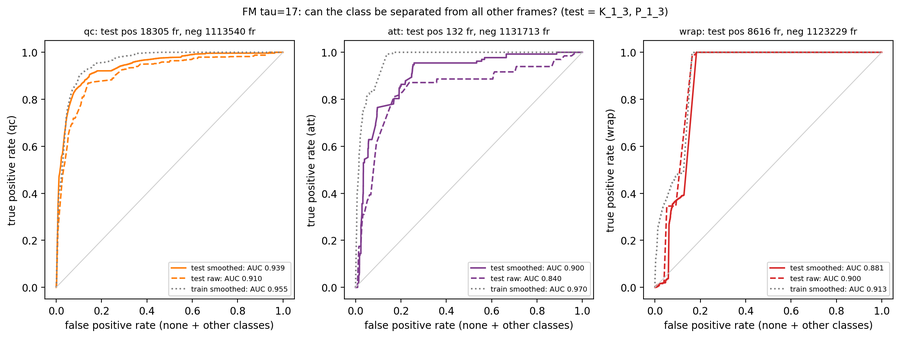

  fig figures/05_score_hist__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_roc__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_score_hist__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_roc__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


... (5 outputs left out)

  fig figures/05_roc__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_score_hist__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_roc__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


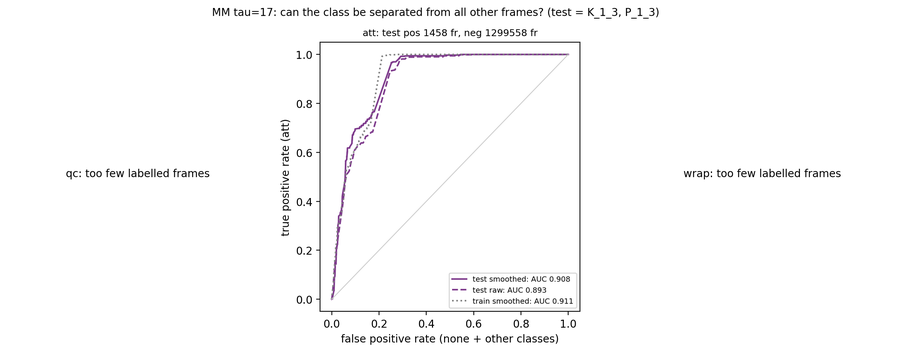

  fig figures/05_score_hist__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_roc__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_score_hist__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png


  fig figures/05_state_maps__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__test.png
  csv data/05_detection__all__dmax150-bd7-dnu-of-bz4-bth8-minv20__test.csv  rows 27
unit  tau class  test_pos_frames  test_pos_rate  auc_test_raw  auc_test_smoothed  ap_test_smoothed  precision_test  recall_test  f1_test  negatives_flagged_test  bouts_found_test  bouts_test
  FM    5    qc            18305          0.016         0.908              0.938             0.300           0.356        0.528    0.426                   0.016              43.0        66.0
  FM    5   att              132          0.000         0.789              0.882             0.001           0.000        0.000    0.000                   0.002               0.0         7.0
  FM    5  wrap             8616          0.008         0.933              0.915             0.050           0.022        0.016    0.019                   0.006               1.0         4.0
  FM    7    qc            18305          0.016         0.908       

In [11]:
# Step 5: detection of qc / att / wrap with train-fitted cluster scores, evaluated on the test trials.
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
L.clear_log("05")
DET, SCORES = [], {}
DEC = P4.decode(np.arange(N_STATES), WIDTHS)
for unit in UNITS:
    tr, te = load_micro(unit, "train"), load_micro(unit, "test")
    y_tr, y_te = labels_for(tr), labels_for(te)
    b_tr, b_te = blocks_of(tr), blocks_of(te)
    st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
    for tau in TAUS_FULL[unit]:
        tp = tau_p(tau)
        lab = LABELS[("train", unit, tau)]
        k = int(lab.max()) + 1
        cl_tr = np.where(st_tr >= 0, lab[np.clip(st_tr, 0, None)], -1)
        cl_te = np.where(st_te >= 0, lab[np.clip(st_te, 0, None)], -1)
        nC = len(DETECT_CLASSES)
        fig_r, ax_r = plt.subplots(1, nC, figsize=(5 * nC, 4.6), squeeze=False)
        fig_h, ax_h = plt.subplots(1, nC, figsize=(5 * nC, 3.8), squeeze=False)
        fig_m, ax_m = plt.subplots(nC, 4, figsize=(16, 3.6 * nC), squeeze=False)
        score_tab = pd.DataFrame({"cluster": np.arange(k), "n_frames_train": np.bincount(cl_tr[cl_tr >= 0], minlength=k)})
        for j, c in enumerate(DETECT_CLASSES):
            ytr, yte = P4.detection_target(y_tr, c), P4.detection_target(y_te, c)
            row = {"unit": unit, "tau": tau, "class": c, "train_pos_frames": int((ytr == 1).sum()),
                   "test_pos_frames": int((yte == 1).sum()), "test_neg_frames": int((yte == 0).sum())}
            if row["train_pos_frames"] < MIN_POS or row["test_pos_frames"] < MIN_POS:
                row["note"] = f"fewer than {MIN_POS} labelled frames in train or test"
                DET.append(row)
                for ax in (ax_r[0, j], ax_h[0, j], *ax_m[j]):
                    ax.text(0.5, 0.5, f"{c}: too few labelled frames", ha="center", transform=ax.transAxes)
                    ax.set_axis_off()
                continue
            sc = P4.cluster_scores(cl_tr, ytr, k, PRIOR_FRAMES)
            okf = (ytr >= 0) & (cl_tr >= 0)
            base = float(ytr[okf].mean())
            score_tab[f"P_{c}"] = sc
            raw_tr, raw_te = P4.frame_scores(cl_tr, sc, base), P4.frame_scores(cl_te, sc, base)
            w = SMOOTH_FRAMES[c]
            sm_tr = P4.rolling_mean_blocks(raw_tr, b_tr, w)
            sm_te = P4.rolling_mean_blocks(raw_te, b_te, w)
            thr, f1_tr = P4.best_f1_threshold(sm_tr, ytr)
            SCORES[(unit, tau, c)] = (sc, base, thr)
            ok_tr, ok_te = ytr >= 0, yte >= 0
            pred = sm_te >= thr
            tpos = int((pred & (yte == 1)).sum())
            fpos = int((pred & (yte == 0)).sum())
            prec = tpos / max(tpos + fpos, 1)
            rec = tpos / max(int((yte == 1).sum()), 1)
            found, total = P4.bout_recall(yte, pred, b_te)
            row.update({
                "test_pos_rate": float(yte[ok_te].mean()),
                "auc_train_smoothed": float(roc_auc_score(ytr[ok_tr], sm_tr[ok_tr])),
                "auc_test_raw": float(roc_auc_score(yte[ok_te], raw_te[ok_te])),
                "auc_test_smoothed": float(roc_auc_score(yte[ok_te], sm_te[ok_te])),
                "ap_test_smoothed": float(average_precision_score(yte[ok_te], sm_te[ok_te])),
                "threshold": thr, "f1_train": f1_tr, "precision_test": prec, "recall_test": rec,
                "f1_test": 2 * prec * rec / max(prec + rec, 1e-12),
                "negatives_flagged_test": fpos / max(int((yte == 0).sum()), 1),
                "bouts_found_test": found, "bouts_test": total,
                "smoothing_frames": w})
            DET.append(row)
            # ROC
            ax = ax_r[0, j]
            for yv, sv, style, nm in ((yte, sm_te, "-", "test smoothed"), (yte, raw_te, "--", "test raw"),
                                     (ytr, sm_tr, ":", "train smoothed")):
                okv = yv >= 0
                fpr, tpr, _t = roc_curve(yv[okv], sv[okv])
                ax.plot(fpr, tpr, style, color=CLASS_COLOR[c] if nm != "train smoothed" else "0.5",
                        label=f"{nm}: AUC {roc_auc_score(yv[okv], sv[okv]):.3f}")
            ax.plot([0, 1], [0, 1], color="0.8", lw=0.8)
            ax.set_xlabel("false positive rate (none + other classes)")
            ax.set_ylabel(f"true positive rate ({c})")
            ax.set_title(f"{c}: test pos {row['test_pos_frames']} fr, neg {row['test_neg_frames']} fr", fontsize=9)
            ax.legend(fontsize=7, loc="lower right")
            # score distributions
            ax = ax_h[0, j]
            bins = np.linspace(0, max(float(np.nanmax(sm_te[ok_te])), thr * 1.2, 1e-3), 60)
            ax.hist(sm_te[yte == 0], bins=bins, density=True, histtype="step", color="0.4", label="negatives")
            ax.hist(sm_te[yte == 1], bins=bins, density=True, histtype="step", color=CLASS_COLOR[c], lw=1.6, label=c)
            ax.axvline(thr, color="k", ls="--", lw=1)
            ax.set_yscale("log")
            ax.set_xlabel(f"smoothed P({c} | cluster), test")
            ax.set_title(f"{c}: precision {prec:.2f}, recall {rec:.2f}, bouts {found}/{total}", fontsize=9)
            ax.legend(fontsize=7)
            # where the class lives in state space
            sets = (("train, labelled " + c, st_tr[(ytr == 1) & (st_tr >= 0)]),
                    ("test, predicted " + c, st_te[pred & (st_te >= 0)]))
            for q, (nm, stv) in enumerate(sets):
                d = DEC[stv]
                H1 = np.zeros((WIDTHS[2], WIDTHS[3]))
                np.add.at(H1, (d[:, 2], d[:, 3]), 1)
                H2 = np.zeros((WIDTHS[0], WIDTHS[1]))
                np.add.at(H2, (d[:, 0], d[:, 1]), 1)
                a1, a2 = ax_m[j, 2 * q], ax_m[j, 2 * q + 1]
                a1.imshow(H1.T, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], cmap="Greys")
                a1.set_xlabel(f"theta_a ({UNITS[unit][0][0]})", fontsize=7)
                a1.set_ylabel(f"theta_b ({UNITS[unit][0][1]})", fontsize=7)
                a1.set_title(f"{nm}: {len(stv)} frames", fontsize=8)
                a2.imshow(H2.T, origin="lower", aspect="auto", cmap="Greys")
                a2.set_xticks(np.arange(WIDTHS[0]), [f"{e:.0f}" for e in EDGES[0][:-1]], fontsize=6)
                a2.set_yticks(np.arange(WIDTHS[1]), [f"{e:.0f}" for e in EDGES[1][:-1]], fontsize=6)
                a2.set_xlabel("D_xy bin lower edge (mm)", fontsize=7)
                a2.set_ylabel("dz bin lower edge (mm)", fontsize=7)
                a2.set_title(nm, fontsize=8)
        L.save_csv(score_tab, "05", "cluster_scores", unit, tp, "train", verbose=False)
        fig_r.suptitle(f"{unit} tau={tau}: can the class be separated from all other frames? (test = K_1_3, P_1_3)", fontsize=10)
        save_fig(fig_r, "05", "roc", unit, tp, "test", show=(tau == 17))
        fig_h.suptitle(f"{unit} tau={tau}: smoothed class score on the test trials; dashed = threshold fixed on train", fontsize=10)
        fig_h.tight_layout()
        save_fig(fig_h, "05", "score_hist", unit, tp, "test")
        fig_m.suptitle(f"{unit} tau={tau}: where the class lives in state space (frame counts)", fontsize=10)
        fig_m.tight_layout()
        save_fig(fig_m, "05", "state_maps", unit, tp, "test")
DET_T = pd.DataFrame(DET)
L.save_csv(DET_T, "05", "detection", "all", STATE_P, "test")
cols = ["unit", "tau", "class", "test_pos_frames", "test_pos_rate", "auc_test_raw", "auc_test_smoothed",
        "ap_test_smoothed", "precision_test", "recall_test", "f1_test", "negatives_flagged_test", "bouts_found_test", "bouts_test"]
print(DET_T[[c for c in cols if c in DET_T.columns]].round(3).to_string(index=False))

  fig figures/05_ethogram_qc__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


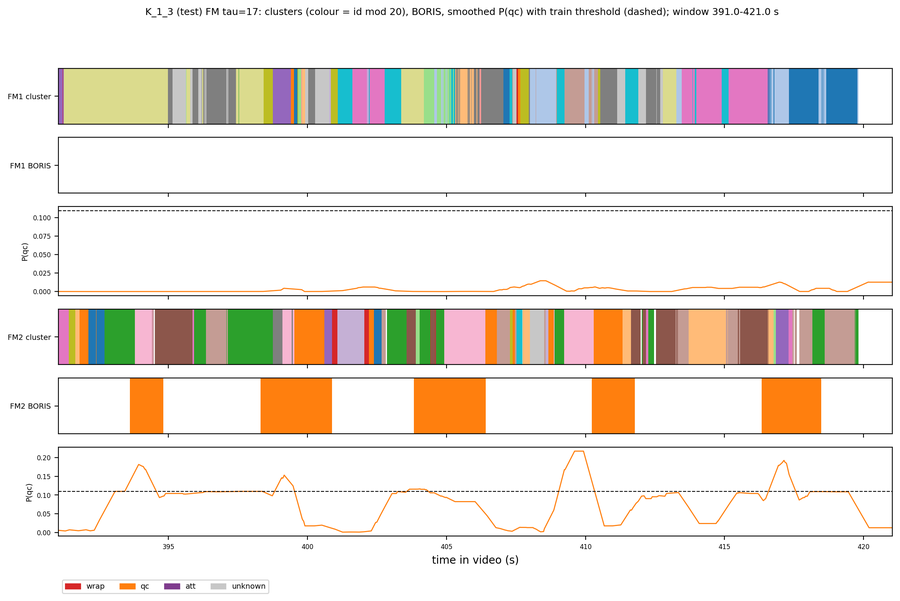

  fig figures/05_ethogram_qc__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_qc__FM__tau5-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


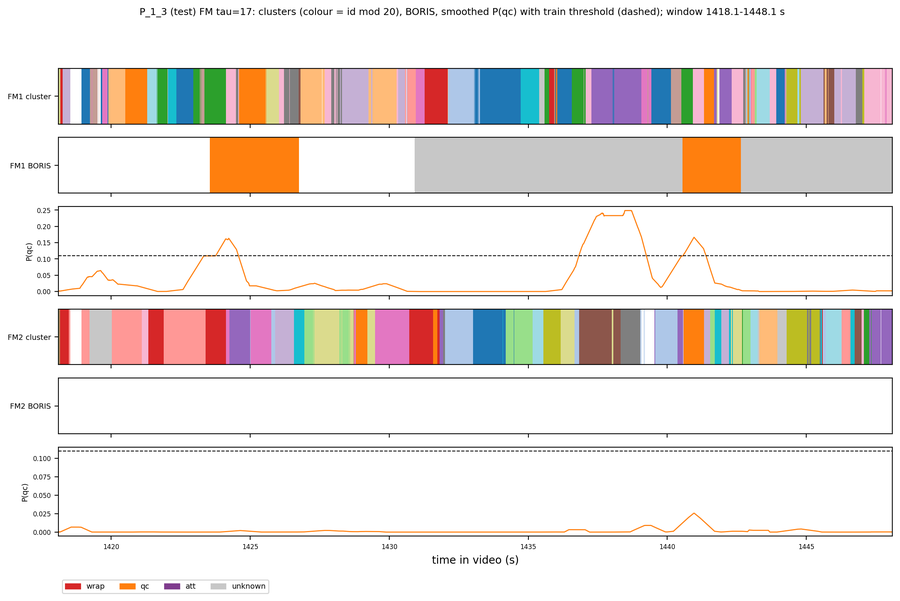

  fig figures/05_ethogram_qc__FM__tau20-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


  fig figures/05_ethogram_qc__FM__tau100-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


  fig figures/05_ethogram_att__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_att__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_att__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


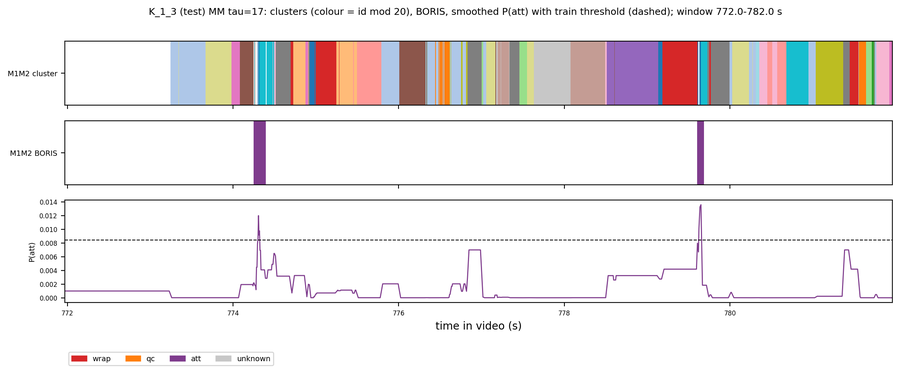

  fig figures/05_ethogram_att__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__K_1_3.png


  fig figures/05_ethogram_att__MM__tau1-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png
  fig figures/05_ethogram_att__MM__tau7-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


  fig figures/05_ethogram_att__MM__tau17-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


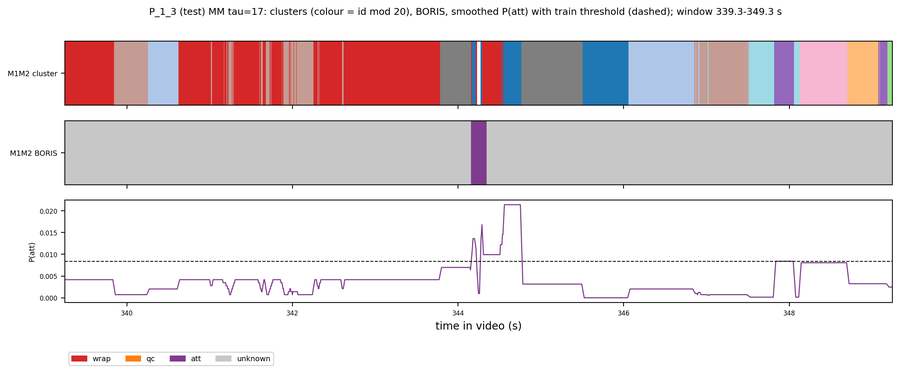

  fig figures/05_ethogram_att__MM__tau70-dmax150-bd7-dnu-of-bz4-bth8-minv20__P_1_3.png


In [12]:
# Step 5 (continued): ethograms on the test trials: clusters, BORIS, class score and threshold.
for e, c, unit, win_s in ETHOGRAM_SPECS:
    set_e = "train" if e in TRAIN_EXPERIMENTS else "test"
    mic = load_micro(unit, set_e)
    ei = [str(x) for x in mic["exp_names"]].index(e)
    show_copies = COPIES[unit] if unit == "FM" else COPIES[unit][:1]
    fps = float(load_exp(e)["fps"])
    win = int(win_s * fps)
    dens = np.zeros(len(load_exp(e)["frames"]))
    for cp in show_copies:
        dens += P4.base_class(FRAME_LABELS[(e, cp)]) == c
    cs = np.concatenate([[0], np.cumsum(dens)])
    sums = cs[win:] - cs[:-win]
    best = np.flatnonzero(sums == sums.max())
    start = int(best[len(best) // 2])   # middle of the tied windows, so the bouts sit inside the window
    t = np.arange(start, start + win) / fps
    for tau in TAUS_FULL[unit]:
        if (unit, tau, c) not in SCORES:
            continue
        sc, base, thr = SCORES[(unit, tau, c)]
        lab = LABELS[("train", unit, tau)]
        fig, axes = plt.subplots(3 * len(show_copies), 1, figsize=(14, 1.15 * 3 * len(show_copies) + 1), sharex=True,
                                 gridspec_kw={"height_ratios": [1, 1, 1.6] * len(show_copies)})
        for r, cp in enumerate(show_copies):
            ci = [str(x) for x in mic["copy_names"]].index(cp)
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            st_full = mic["state"][m].astype(np.int64)
            cl_full = np.where(st_full >= 0, lab[np.clip(st_full, 0, None)], -1)
            score = P4.rolling_mean_blocks(P4.frame_scores(cl_full, sc, base), np.zeros(len(cl_full)), SMOOTH_FRAMES[c])
            cl = cl_full[start:start + win]
            code_ = np.where(cl < 0, 0, cl % 20 + 1)
            ax = axes[3 * r]
            ax.imshow(code_[None, :], aspect="auto", cmap=ListedColormap(["white"] + list(plt.get_cmap("tab20").colors)),
                      vmin=-0.5, vmax=20.5, extent=[t[0], t[-1], 0, 1], interpolation="nearest")
            ax.set_yticks([0.5], [f"{cp} cluster"], fontsize=7)
            ax2 = axes[3 * r + 1]
            bl = P4.base_class(FRAME_LABELS[(e, cp)][start:start + win])
            for cname in list(LABEL_CLASSES) + ["unknown"]:
                a0, a1 = S.bool_runs(bl == cname)
                for s0, s1 in zip(a0, a1):
                    ax2.axvspan(t[s0], t[min(s1, len(t) - 1)], color=CLASS_COLOR[cname], lw=0)
            ax2.set_ylim(0, 1)
            ax2.set_yticks([0.5], [f"{cp} BORIS"], fontsize=7)
            ax3 = axes[3 * r + 2]
            ax3.plot(t, score[start:start + win], color=CLASS_COLOR[c], lw=1)
            ax3.axhline(thr, color="k", ls="--", lw=0.8)
            ax3.set_ylabel(f"P({c})", fontsize=7)
            ax3.tick_params(labelsize=6)
        handles = [plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[n]) for n in list(LABEL_CLASSES) + ["unknown"]]
        axes[-1].legend(handles, list(LABEL_CLASSES) + ["unknown"], ncol=4, fontsize=7, loc="upper left",
                        bbox_to_anchor=(0, -0.45))
        axes[-1].set_xlabel("time in video (s)")
        fig.suptitle(f"{exp_short(e)} ({set_e}) {unit} tau={tau}: clusters (colour = id mod 20), BORIS, smoothed P({c}) "
                     f"with train threshold (dashed); window {start / fps:.1f}-{(start + win) / fps:.1f} s", fontsize=9)
        save_fig(fig, "05", f"ethogram_{c}", unit, tau_p(tau), exp_short(e), show=(tau == 17))
L.log("05", "done")

## Step 6 — 总结表与输出清单

把 Step 3–5 的关键数字合并成 `summary.csv`（每个单元 × τ 一行；Step 5 的指标按类别展开成列，例如 `auc_test_smoothed_qc`），并列出输出目录里的文件。

In [13]:
# Step 6: summary table and file listing.
det_cols = ["auc_test_smoothed", "ap_test_smoothed", "test_pos_rate", "precision_test", "recall_test",
            "bouts_found_test", "bouts_test"]
wide = DET_T.pivot_table(index=["unit", "tau"], columns="class", values=[c for c in det_cols if c in DET_T.columns])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
summ = SUMMARY_T.merge(GEN_T, on=["unit", "tau"]).merge(wide.reset_index(), on=["unit", "tau"], how="left")
summ.to_csv(L.root / "summary.csv", index=False)
print("taus analysed in full:", TAUS_FULL)
print(summ.round(3).T.to_string())
print("\noutput folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

taus analysed in full: {'FM': [5, 7, 17, 20, 100], 'MM': [1, 7, 17, 70]}
                                             0        1        2        3        4         5        6        7        8
unit                                        FM       FM       FM       FM       FM        MM       MM       MM       MM
tau                                          5        7       17       20      100         1        7       17       70
tau_s                                     0.03    0.042    0.102     0.12    0.602     0.006    0.042    0.102    0.422
n_clusters                                 892      682      309      262       52      1811      559      233       45
n_clusters_95pct                           678      517      224      189       26      1384      424      173       23
largest_cluster_frame_fraction           0.009    0.019     0.04    0.027    0.193     0.005    0.019    0.031    0.172
effective_clusters                     552.421  411.792  173.333  160.931   17.307  119